# Signature Detection with YOLOX-s (Apache 2.0) - improved end-to-end notebook
**setup -> data -> negatives -> train with early stopping -> tune thresholds -> evaluate -> export (best.pt, signature.onnx, history.json, onnx_infer.py).**

YOLOX (Megvii) and its pretrained weights are **Apache 2.0**, so they are allowed for closed-source commercial use. No Ultralytics code is used.
Dataset: `AimaArshad/signature-detection-yolox` (COCO format, 1 class: `signature`).

## What is new compared with the first notebook
| New | Why |
|---|---|
| **Early stopping on validation mAP@.50** (patience) | Stops when the model stops improving, so it does not overfit. The best weights are kept by that metric. |
| **`history.json`** | Per-epoch mAP@.50, mAP@.50:.95 and loss, saved while training. Survives Kaggle disconnects. |
| **Negative pages** (signature-free) | Teaches the model what a signature is *not* -> fewer false positives. |
| **IoU explained with a picture** | Shows why a box counts as correct or wrong. |
| **Confidence + NMS threshold tuning** | Picks the thresholds automatically on the *validation* set. |
| **Honest final report on TEST** | mAP@.50, mAP@.50:.95, mAP@.75, Precision, Recall, F1. |
| **Mistake gallery** | Shows the worst false positives and misses. |
| **Export bundle** | `best.pt`, `signature.onnx`, `history.json`, `onnx_infer.py` + automatic ONNX check. |

## Before you run anything
1. Settings -> **Accelerator: GPU T4 x2** (or P100)
2. Settings -> **Internet: On**
3. **Add-ons -> Secrets**: `HF_TOKEN` must exist and be **attached** to this notebook (toggle on)

## Order of cells (run top to bottom)
| # | Cell | What it does |
|---|------|--------------|
| 1 | Settings + imports | All options in one place |
| 2 | Environment check | GPU, internet, Hugging Face token |
| 3 | Install YOLOX | Clones YOLOX, installs deps, patches NumPy, downloads yolox_s.pth |
| 4 | Get the dataset | Downloads/extracts from Hugging Face (skips if already there) |
| 5 | Verify data | Counts images/boxes per split (and images without signatures) |
| 6 | Add negative pages | Builds signature-free pages from training pages |
| 7 | Write config | Creates the YOLOX-s experiment file |
| 8 | **Train + early stopping** | Trains, watches mAP@.50, writes `history.json` |
| 9 | Training curves | mAP / loss per epoch, best epoch marked |
| 10 | Load best model | Helper functions for inference |
| 11 | IoU explained | Visual demo of IoU |
| 12 | Tune confidence threshold | Precision / Recall / F1 sweep on validation |
| 13 | Tune NMS threshold | Removes duplicate boxes |
| 14 | **Final evaluation** | mAP + Precision/Recall/F1 on validation and **test** |
| 15 | See predictions + mistakes | Green = prediction, blue = real box, red = the mistake |
| 16 | **Export** | `best.pt`, `signature.onnx`, `history.json`, `onnx_infer.py`, zip |
| 17 | Test the ONNX files | ONNX vs PyTorch agreement + a sample picture |

**First run with `QUICK_TEST = True`** (about 10-15 min). When it works end to end, set `QUICK_TEST = False` and run everything again for the real training.

## Cell 1: Settings and imports
Change options here only. Everything else reads from this cell.

In [2]:
# ============ CELL 1: SETTINGS AND IMPORTS ============
import os, sys, re, glob, json, time, random, shutil, subprocess, warnings, contextlib, io
from collections import defaultdict
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# ---------------- SETTINGS YOU CAN CHANGE ----------------
QUICK_TEST       = False  # True = tiny 2-epoch test run (about 10-15 min). Set False for the real run.
EPOCHS           = 30     # MAXIMUM number of epochs. Early stopping may finish sooner.
BATCH_SIZE       = 16      # If "CUDA out of memory" -> use 8
INPUT_SIZE       = 640     # 640 = fast. Small signatures on big pages? Try 800 together with BATCH_SIZE = 8

# --- Early stopping (Cell 8) ---
MONITOR          = "ap50"  # metric to watch: "ap50" = mAP@.50 (recommended) | "ap50_95" = mAP@.50:.95
PATIENCE         = 8       # stop after this many evaluations in a row without a new best score
MIN_EPOCHS       = 15      # never stop before this epoch (lets the model get past the early noisy epochs)
MIN_DELTA        = 0.0     # how much better counts as "improved" (0.0 = any new maximum)
EVAL_INTERVAL    = 1       # evaluate on validation every N epochs (patience counts evaluations)

# --- Fewer false positives ---
ADD_NEGATIVES    = True   # Cell 6: add signature-free pages to the training set
NEG_RATIO        = 0.10    # number of extra negative pages = 10% of the training images
NEG_MAX          = 2000    # hard cap on how many negative pages are created
PRECISION_TARGET = 0.95    # Cell 12 looks for the confidence threshold that reaches this precision

# --- Thresholds (Cells 12 and 13 tune these automatically on the validation set) ---
CONF_THRESHOLD   = 0.50
NMS_THRESHOLD    = 0.45

CLASSES          = ["signature"]
HF_REPO          = "AimaArshad/signature-detection-yolox"
# ----------------------------------------------------------

assert MONITOR in ("ap50", "ap50_95"), 'MONITOR must be "ap50" or "ap50_95"'
if QUICK_TEST:
    EPOCHS, MAX_TRAIN, MAX_VAL, EVAL_LIMIT, SWEEP_LIMIT = 2, 1500, 300, 300, 300
    EVAL_INTERVAL = 1
else:
    MAX_TRAIN = MAX_VAL = EVAL_LIMIT = None      # None = use everything
    SWEEP_LIMIT = 1500                           # validation images used to tune the thresholds

# Paths (normally never change)
WORK      = "/kaggle/working"
YOLOX_DIR = f"{WORK}/YOLOX"
DATA_DIR  = f"{WORK}/signature_coco"             # dataset gets extracted here
EXP_NAME  = "yolox_s_signature"
EXP_FILE  = f"{YOLOX_DIR}/exps/custom/{EXP_NAME}.py"
OUT_DIR   = f"{YOLOX_DIR}/YOLOX_outputs/{EXP_NAME}"

# Helps old YOLOX code load checkpoints on new PyTorch
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
os.environ["PYTHONPATH"] = YOLOX_DIR + os.pathsep + os.environ.get("PYTHONPATH", "")
os.environ["WANDB_DISABLED"] = "true"

def sh(cmd, cwd=None):
    """Run a shell command quietly and return the result."""
    return subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)

random.seed(42); np.random.seed(42); torch.manual_seed(42)
print("Settings OK | QUICK_TEST =", QUICK_TEST, "| max EPOCHS =", EPOCHS, "| BATCH =", BATCH_SIZE,
      "| early stopping on", MONITOR, "with patience", PATIENCE)

Settings OK | QUICK_TEST = False | max EPOCHS = 30 | BATCH = 16 | early stopping on ap50 with patience 8


## Cell 2: Check GPU, internet and load your Hugging Face token
The token comes from Kaggle Secrets (never paste it into code).

In [3]:
# ============ CELL 2: ENVIRONMENT CHECK + HF TOKEN ============
import urllib.request
print("PyTorch:", torch.__version__)
if torch.cuda.is_available():
    print("GPUs   :", torch.cuda.device_count(), "x", torch.cuda.get_device_name(0), "-> OK")
else:
    raise RuntimeError("GPU NOT FOUND. Settings -> Accelerator -> GPU T4 x2 (or P100), then restart the session.")
try:
    urllib.request.urlopen("https://github.com", timeout=8)
    print("Internet: ON -> OK")
except Exception:
    print("Internet: OFF. Settings -> Internet -> On, then restart session.")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("MODEL_TRAINING_TOKEN")
    print("HF token: loaded from Kaggle Secrets -> OK")
except Exception as e:
    print("HF token: not found (downloads still work, just slower). Check Add-ons -> Secrets ->", e)

PyTorch: 2.11.0+cu130
GPUs   : 2 x Tesla T4 -> OK
Internet: ON -> OK
HF token: loaded from Kaggle Secrets -> OK


## Cell 3: Install YOLOX
Clones the official Apache 2.0 repo, installs small dependencies (including `onnx` and `onnxruntime` for the export), fixes a NumPy compatibility issue, and downloads the pretrained `yolox_s.pth`.

In [4]:
# ============ CELL 3: INSTALL YOLOX ============
if not os.path.exists(f"{YOLOX_DIR}/tools/train.py"):
    sh(f"rm -rf {YOLOX_DIR} && git clone -q https://github.com/Megvii-BaseDetection/YOLOX.git {YOLOX_DIR}", cwd=WORK)
assert os.path.exists(f"{YOLOX_DIR}/tools/train.py"), "YOLOX download failed. Is Internet ON?"

sh("pip install -q loguru tabulate thop psutil ninja pycocotools tensorboard huggingface_hub onnx onnxruntime")
sh("pip install -q -e . --no-deps", cwd=YOLOX_DIR)

# Old YOLOX code uses np.int / np.float / np.bool, which new NumPy removed
pat = re.compile(r"\bnp\.(int|float|bool)\b")
patched = 0
for f in glob.glob(f"{YOLOX_DIR}/**/*.py", recursive=True):
    txt = open(f, encoding="utf-8").read()
    new = pat.sub(r"\1", txt)
    if new != txt:
        open(f, "w", encoding="utf-8").write(new); patched += 1
print("Compatibility patch applied to", patched, "file(s)")

WEIGHTS = f"{YOLOX_DIR}/yolox_s.pth"
if not os.path.exists(WEIGHTS):
    sh("wget -q https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_s.pth", cwd=YOLOX_DIR)
print("YOLOX ready       :", os.path.exists(f"{YOLOX_DIR}/tools/train.py"))
print("Pretrained weights:", os.path.exists(WEIGHTS))

sys.path.insert(0, YOLOX_DIR) 
os.chdir(YOLOX_DIR)

Compatibility patch applied to 0 file(s)
YOLOX ready       : True
Pretrained weights: True


## Cell 4: Get the dataset
If you already extracted it to `/kaggle/working/signature_coco`, this cell just confirms that and does nothing. In a **new session** it downloads everything again from Hugging Face (about 3.6 GB).

In [5]:
# ============ CELL 4: GET THE DATASET ============
ann_train = f"{DATA_DIR}/annotations/instances_train2017.json"
if os.path.exists(ann_train):
    print("Dataset already extracted at", DATA_DIR, "-> skipping download")
else:
    print("Downloading dataset from Hugging Face (a few minutes)...")
    from huggingface_hub import hf_hub_download
    script = hf_hub_download(HF_REPO, "5_download_and_extract.py", repo_type="dataset")
    p = subprocess.Popen([sys.executable, script, "--repo", HF_REPO, "--out", DATA_DIR],
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if "%|" not in line:                 # hide progress-bar spam
            print(line.rstrip()[:200])
    p.wait()
    assert p.returncode == 0, "Download failed. Check the messages above."
print("Contents:", sorted(os.listdir(DATA_DIR)))

Dataset already extracted at /kaggle/working/signature_coco -> skipping download
Contents: ['.cache', '.gitattributes', '5_download_and_extract.py', 'README.md', 'annotations', 'exp_signature_yolox_s.py', 'test2017', 'train2017', 'val2017']


## Cell 5: Verify the data (and build a small subset for QUICK_TEST)
Checks that all 3 splits have images + annotations and shows how many images contain **no** signature (those are "negative" images). With `QUICK_TEST=True` it also makes small annotation files so the test run is fast (images are not copied).

In [6]:
# ============ CELL 5: VERIFY DATA ============
SPLITS = {"train": "train2017", "val": "val2017", "test": "test2017"}
A = f"{DATA_DIR}/annotations"
CAT_ID = None
for s, folder in SPLITS.items():
    jp, d = f"{A}/instances_{folder}.json", f"{DATA_DIR}/{folder}"
    assert os.path.exists(jp), f"Missing {jp}"
    assert os.path.isdir(d),   f"Missing folder {d}"
    j = json.load(open(jp))
    first = os.path.join(d, j["images"][0]["file_name"])
    assert os.path.exists(first), f"Image listed in JSON not found: {first} (nested folder?)"
    n_empty = len(j["images"]) - len({a["image_id"] for a in j["annotations"]})
    print(f"{s:>5}: {len(j['images']):>6} images | {len(j['annotations']):>6} boxes | "
          f"{n_empty:>5} images with NO signature | categories: {j['categories']}")
    if CAT_ID is None:
        CAT_ID = sorted(c["id"] for c in j["categories"])[0]

def make_subset(src, dst, n):
    j = json.load(open(src))
    imgs = random.Random(42).sample(j["images"], min(n, len(j["images"])))
    ids = {i["id"] for i in imgs}
    j["images"] = imgs
    j["annotations"] = [a for a in j["annotations"] if a["image_id"] in ids]
    json.dump(j, open(dst, "w"))
    print(f"  subset {os.path.basename(dst)}: {len(imgs)} images, {len(j['annotations'])} boxes")

if QUICK_TEST:
    print("QUICK_TEST -> building small subsets")
    make_subset(f"{A}/instances_train2017.json", f"{A}/instances_train_small.json", MAX_TRAIN)
    make_subset(f"{A}/instances_val2017.json",   f"{A}/instances_val_small.json",   MAX_VAL)
    TRAIN_ANN, VAL_ANN = "instances_train_small.json", "instances_val_small.json"
else:
    TRAIN_ANN, VAL_ANN = "instances_train2017.json", "instances_val2017.json"
print("Using:", TRAIN_ANN, "|", VAL_ANN)

train:  26632 images |  32137 boxes |     0 images with NO signature | categories: [{'id': 1, 'name': 'signature', 'supercategory': 'none'}]
  val:   2418 images |   3041 boxes |     0 images with NO signature | categories: [{'id': 1, 'name': 'signature', 'supercategory': 'none'}]
 test:   2333 images |   2991 boxes |     0 images with NO signature | categories: [{'id': 1, 'name': 'signature', 'supercategory': 'none'}]
Using: instances_train2017.json | instances_val2017.json


## Cell 6: Add negative (signature-free) pages  -> fewer false positives
A detector that only ever sees pages **with** signatures learns to "find something", so printed text, stamps and lines can fool it. Negative pages teach it what a signature is **not**.

This cell takes a random 10% of your **training** pages and paints each signature box with the colour of the paper around it. The result is the same form (same printed text, same signature line) but **without** a signature, saved as a new image with no annotation. Only training pages are used, so nothing leaks into validation or test.

Set `ADD_NEGATIVES = False` in Cell 1 to skip this. If your dataset already has many images without signatures (see Cell 5), you can lower `NEG_RATIO`.

building negative pages:   0%|          | 0/2000 [00:00<?, ?it/s]

Added 2000 negative pages. Training annotations now: instances_train2017_neg.json


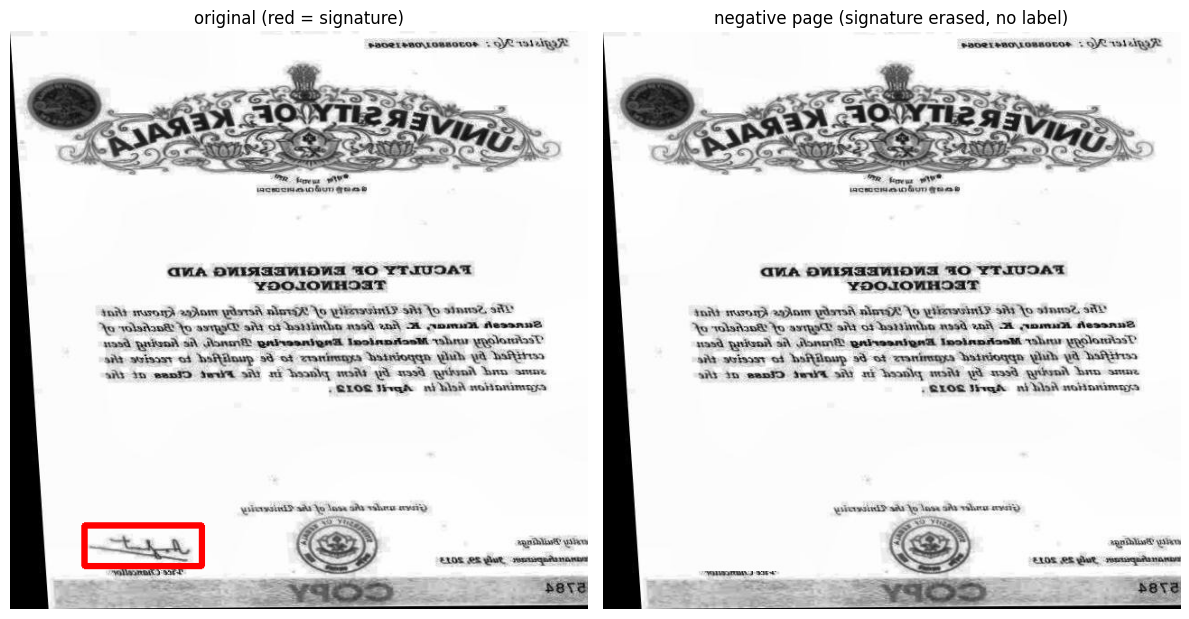

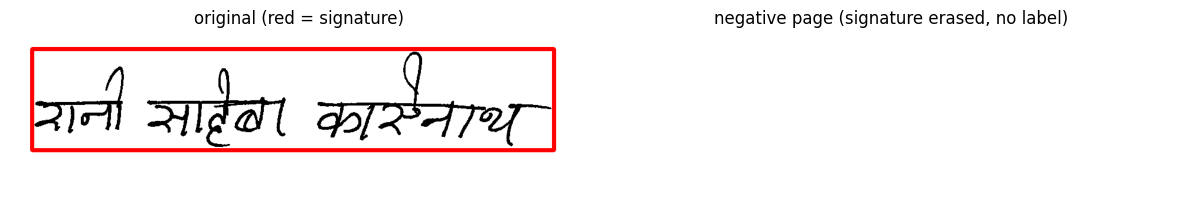

In [7]:
# ============ CELL 6: ADD NEGATIVE (SIGNATURE-FREE) PAGES ============
def erase_boxes(img, boxes):
    """Paint each signature box with the colour of the paper around it."""
    h, w = img.shape[:2]
    for x, y, bw, bh in boxes:
        pad = max(6, int(0.03 * max(bw, bh)))
        x1, y1 = max(0, int(x) - pad), max(0, int(y) - pad)
        x2, y2 = min(w, int(x + bw) + pad), min(h, int(y + bh) + pad)
        if x2 <= x1 or y2 <= y1:
            continue
        rx1, ry1, rx2, ry2 = max(0, x1 - 20), max(0, y1 - 20), min(w, x2 + 20), min(h, y2 + 20)
        ring = img[ry1:ry2, rx1:rx2].copy()
        keep = np.ones(ring.shape[:2], bool)
        keep[y1 - ry1:y2 - ry1, x1 - rx1:x2 - rx1] = False
        fill = np.median(ring[keep], axis=0) if keep.any() else np.array([255, 255, 255])
        img[y1:y2, x1:x2] = fill.astype(np.uint8)
    return img

def make_negatives(src_name, dst_name, img_dir, ratio, max_new, seed=42):
    j = json.load(open(f"{A}/{src_name}"))
    boxes = defaultdict(list)
    for a in j["annotations"]:
        boxes[a["image_id"]].append(a["bbox"])
    with_sig = [im for im in j["images"] if im["id"] in boxes]
    n_new = min(int(len(j["images"]) * ratio), max_new, len(with_sig))
    chosen = random.Random(seed).sample(with_sig, n_new)
    next_id = max(im["id"] for im in j["images"]) + 1
    new_imgs, pairs = [], []
    for im in tqdm(chosen, desc="building negative pages"):
        name = f"neg_{im['id']}.jpg"
        out = f"{img_dir}/{name}"
        if not os.path.exists(out):
            img = cv2.imread(f"{img_dir}/{im['file_name']}")
            if img is None:
                continue
            cv2.imwrite(out, erase_boxes(img, boxes[im["id"]]), [cv2.IMWRITE_JPEG_QUALITY, 92])
        new_imgs.append({"id": next_id, "file_name": name, "width": im["width"], "height": im["height"]})
        pairs.append((im, name, boxes[im["id"]]))
        next_id += 1
    j["images"] = j["images"] + new_imgs                  # new images have NO annotations = negatives
    json.dump(j, open(f"{A}/{dst_name}", "w"))
    return len(new_imgs), pairs

if ADD_NEGATIVES:
    base = TRAIN_ANN.replace("_neg.json", ".json")         # safe if this cell is run twice
    TRAIN_ANN = base.replace(".json", "_neg.json")
    n_neg, pairs = make_negatives(base, TRAIN_ANN, f"{DATA_DIR}/train2017", NEG_RATIO, NEG_MAX)
    print(f"Added {n_neg} negative pages. Training annotations now: {TRAIN_ANN}")
    for im, name, bxs in pairs[:2]:                        # quick visual check
        before = cv2.cvtColor(cv2.imread(f"{DATA_DIR}/train2017/{im['file_name']}"), cv2.COLOR_BGR2RGB)
        for x, y, w_, h_ in bxs:
            cv2.rectangle(before, (int(x), int(y)), (int(x + w_), int(y + h_)), (255, 0, 0), 6)
        after = cv2.cvtColor(cv2.imread(f"{DATA_DIR}/train2017/{name}"), cv2.COLOR_BGR2RGB)
        fig, ax = plt.subplots(1, 2, figsize=(12, 7))
        ax[0].imshow(before); ax[0].set_title("original (red = signature)")
        ax[1].imshow(after);  ax[1].set_title("negative page (signature erased, no label)")
        for a_ in ax: a_.axis("off")
        plt.tight_layout(); plt.show()
else:
    print("ADD_NEGATIVES = False -> training on the original images only")

## Cell 7: Write the YOLOX-s training config
Creates the experiment file (YOLOX-s size, 1 class). If you change the main settings between runs, old checkpoints are cleared so you start fresh. (Changing `PATIENCE`, `MIN_EPOCHS`, `MIN_DELTA` or `MONITOR` does **not** reset training.)

In [8]:
# ============ CELL 7: WRITE THE YOLOX CONFIG ============
exp_template = """
import os
from yolox.exp import Exp as MyExp

class Exp(MyExp):
    def __init__(self):
        super().__init__()
        self.num_classes = __NC__
        self.depth, self.width = 0.33, 0.50            # YOLOX-s size
        self.data_dir = "__DATA__"
        self.train_ann = "__TRAIN_ANN__"
        self.val_ann = "__VAL_ANN__"
        self.input_size = (__SIZE__, __SIZE__)
        self.test_size = (__SIZE__, __SIZE__)
        self.max_epoch = __EPOCHS__
        self.warmup_epochs = 1
        self.no_aug_epochs = __NOAUG__
        self.eval_interval = __EVAL__
        self.print_interval = 200
        self.data_num_workers = 4
        self.save_history_ckpt = False                 # keep only last + best checkpoints
        self.exp_name = "__NAME__"
"""
cfg = (exp_template.replace("__NC__", str(len(CLASSES))).replace("__DATA__", DATA_DIR)
       .replace("__TRAIN_ANN__", TRAIN_ANN).replace("__VAL_ANN__", VAL_ANN)
       .replace("__SIZE__", str(INPUT_SIZE)).replace("__EPOCHS__", str(EPOCHS))
       .replace("__NOAUG__", "1" if QUICK_TEST else "5").replace("__EVAL__", str(EVAL_INTERVAL))
       .replace("__NAME__", EXP_NAME))
os.makedirs(os.path.dirname(EXP_FILE), exist_ok=True)
open(EXP_FILE, "w").write(cfg)

# If the main settings changed since the last run, start fresh instead of resuming an old run
info_path = f"{WORK}/run_info.json"
info = {"epochs": EPOCHS, "quick": QUICK_TEST, "bs": BATCH_SIZE, "size": INPUT_SIZE,
        "neg": ADD_NEGATIVES, "neg_ratio": NEG_RATIO, "eval": EVAL_INTERVAL}
old = json.load(open(info_path)) if os.path.exists(info_path) else None
if old != info:
    shutil.rmtree(OUT_DIR, ignore_errors=True)
json.dump(info, open(info_path, "w"))
print("Config saved:", EXP_FILE)

Config saved: /kaggle/working/YOLOX/exps/custom/yolox_s_signature.py


## Cell 8: Train with early stopping
Runs YOLOX's own training, plus a small add-on script that:
1. evaluates on the validation set after every epoch (`EVAL_INTERVAL`),
2. watches **mAP@.50** (or the metric you chose in `MONITOR`),
3. keeps the **best weights** by that metric (`best_monitor_ckpt.pth`),
4. **stops** when there is no new best for `PATIENCE` evaluations in a row (never before `MIN_EPOCHS`),
5. writes `history.json` after every epoch.

Example with `PATIENCE = 8`: the best mAP@.50 is 0.85 at epoch 40. If epochs 41-48 never beat 0.85, training stops. If epoch 45 reaches 0.86, the counter goes back to 0.

- **If Kaggle disconnects:** run Cells 1 to 7 again, then this cell. It **resumes** from the last checkpoint and keeps the early-stopping counter.
- For the real run use **Save Version -> Save & Run All (Commit)** so it trains in the background.
- Out of memory? Set `BATCH_SIZE = 8` in Cell 1.
- Early stopping needs a single GPU (`-d 1`), which is also the safest setting on Kaggle.

In [9]:
# ============ CELL 8: TRAIN WITH EARLY STOPPING ============
assert torch.cuda.is_available(), "NO GPU in this session. Settings -> Accelerator -> GPU T4 x2 (or P100), then restart the session and re-run Cells 1-7."
ES_PATH = f"{WORK}/train_es.py"
HIST    = f"{OUT_DIR}/history.json"
LAST    = f"{OUT_DIR}/last_epoch_ckpt.pth"

ES_SCRIPT = r"""
# Runs YOLOX's own tools/train.py and adds: early stopping on validation mAP,
# best-weights saving by that metric, and a history.json log.
import os, sys, json, runpy
import torch
from yolox.core.trainer import Trainer

MONITOR    = os.environ.get("ES_MONITOR", "ap50")
PATIENCE   = int(os.environ.get("ES_PATIENCE", "8"))
MIN_EPOCHS = int(os.environ.get("ES_MIN_EPOCHS", "15"))
MIN_DELTA  = float(os.environ.get("ES_MIN_DELTA", "0.0"))
HIST_PATH  = os.environ["ES_HISTORY"]

STATE = {"epochs": []}
if os.path.exists(HIST_PATH):                       # resuming after a disconnect
    STATE = json.load(open(HIST_PATH))
STATE.update(monitor=MONITOR, patience=PATIENCE, min_epochs=MIN_EPOCHS, min_delta=MIN_DELTA,
             finished=False, stopped_early=False)

def _save():
    os.makedirs(os.path.dirname(HIST_PATH), exist_ok=True)   # FIX: folder may not exist yet
    tmp = HIST_PATH + ".tmp"
    json.dump(STATE, open(tmp, "w"), indent=2)
    os.replace(tmp, HIST_PATH)

def _recompute():
    best, best_ep, bad = -1.0, 0, 0
    for e in sorted(STATE["epochs"], key=lambda e: e["epoch"]):
        if e[MONITOR] > best + MIN_DELTA:
            best, best_ep, bad = e[MONITOR], e["epoch"], 0
        else:
            bad += 1
    STATE.update(best=best, best_epoch=best_ep, bad_evals=bad)

_recompute()
_save()

_orig_eval_and_save = Trainer.evaluate_and_save_model

def evaluate_and_save_model(self):
    exp, real_eval, got = self.exp, self.exp.eval, {}
    def capture(*a, **k):                           # grab the mAP numbers YOLOX computes
        res = real_eval(*a, **k)
        m = res[0] if (isinstance(res, tuple) and len(res) == 2 and isinstance(res[0], (tuple, list))) else res
        got["ap50_95"], got["ap50"] = float(m[0]), float(m[1])
        return res
    exp.eval = capture
    try:
        _orig_eval_and_save(self)                   # YOLOX evaluates + saves last_epoch_ckpt.pth
    finally:
        exp.__dict__.pop("eval", None)
    if "ap50" not in got:
        return
    epoch = self.epoch + 1
    try:
        loss = float(self.meter["total_loss"].avg)
    except Exception:
        loss = None
    entry = {"epoch": epoch, "ap50": got["ap50"], "ap50_95": got["ap50_95"], "train_loss": loss}
    STATE["epochs"] = [e for e in STATE["epochs"] if e["epoch"] != epoch] + [entry]
    _recompute()
    if STATE["best_epoch"] == epoch:                # new best -> keep these weights (model only, small file)
        ck = torch.load(os.path.join(self.file_name, "last_epoch_ckpt.pth"), map_location="cpu", weights_only=False)
        torch.save({"model": ck["model"], "epoch": epoch, "ap50": got["ap50"], "ap50_95": got["ap50_95"]},
                   os.path.join(self.file_name, "best_monitor_ckpt.pth"))
    if epoch >= MIN_EPOCHS and STATE["bad_evals"] >= PATIENCE:
        STATE["stopped_early"] = True
    _save()
    print(f"[EarlyStopping] epoch {epoch:>3} | mAP50 {got['ap50']:.4f} | mAP50:95 {got['ap50_95']:.4f} | "
          f"best {MONITOR} {STATE['best']:.4f} (epoch {STATE['best_epoch']}) | "
          f"no-improvement {STATE['bad_evals']}/{PATIENCE}", flush=True)

def train_in_epoch(self):                           # same loop as YOLOX, plus a stop check
    for self.epoch in range(self.start_epoch, self.max_epoch):
        self.before_epoch()
        self.train_in_iter()
        self.after_epoch()
        if STATE["stopped_early"]:
            print(f"[EarlyStopping] STOP: no new best {MONITOR} for {PATIENCE} evaluations. "
                  f"Best = {STATE['best']:.4f} at epoch {STATE['best_epoch']}", flush=True)
            break
    STATE["finished"] = True
    _save()

Trainer.evaluate_and_save_model = evaluate_and_save_model
Trainer.train_in_epoch = train_in_epoch
print(f"[EarlyStopping] watching {MONITOR} | patience {PATIENCE} | min epochs {MIN_EPOCHS} | min delta {MIN_DELTA}", flush=True)

train_py = os.path.join(os.environ["ES_YOLOX_DIR"], "tools", "train.py")
sys.argv = [train_py] + sys.argv[1:]
runpy.run_path(train_py, run_name="__main__")
"""
open(ES_PATH, "w").write(ES_SCRIPT)

def run_training():
    os.makedirs(OUT_DIR, exist_ok=True)                      # FIX: create the output folder first
    if not os.path.exists(LAST) and os.path.exists(HIST):
        os.remove(HIST)                                   # fresh start -> no stale history
    env = dict(os.environ, ES_MONITOR=MONITOR, ES_PATIENCE=str(PATIENCE), ES_MIN_EPOCHS=str(MIN_EPOCHS),
               ES_MIN_DELTA=str(MIN_DELTA), ES_HISTORY=HIST, ES_YOLOX_DIR=YOLOX_DIR)
    base = f"python -u {ES_PATH} -f {EXP_FILE} -d 1 -b {BATCH_SIZE} --fp16 -o"
    if os.path.exists(LAST):
        print("Checkpoint found -> RESUMING training")
        cmd = f"{base} --resume -c {LAST}"
    else:
        print("Starting fresh from pretrained yolox_s.pth")
        cmd = f"{base} -c {WEIGHTS}"
    keep = re.compile(r"EarlyStopping|epoch: \d+/\d+, iter|Traceback|Error|out of memory|Start training|Training of experiment", re.I)
    logf = open(f"{WORK}/train_log.txt", "a")
    t0 = time.time()
    p = subprocess.Popen(cmd, shell=True, cwd=YOLOX_DIR, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        logf.write(line)
        if keep.search(line):
            print(line.strip()[:220])
    p.wait(); logf.close()
    print(f"\nTraining process ended (exit code {p.returncode}) after {(time.time()-t0)/60:.1f} min")
    if p.returncode != 0:
        print("---- last lines of the log (send these to get help) ----")
        print("".join(open(f"{WORK}/train_log.txt").readlines()[-25:]))

h0 = json.load(open(HIST)) if os.path.exists(HIST) else None
if h0 and h0.get("finished"):
    print(f"Training already finished earlier (best {h0['monitor']} {h0['best']:.4f} at epoch {h0['best_epoch']}). Skipping.")
    print("To train again: change a main setting in Cell 1 (e.g. EPOCHS) and re-run Cells 1-7, or delete", OUT_DIR)
else:
    run_training()

h = json.load(open(HIST)) if os.path.exists(HIST) else None
if h and h.get("finished"):
    why = "EARLY STOPPING triggered" if h.get("stopped_early") else "reached the maximum number of epochs"
    print(f"\nDONE: {why}. Best {h['monitor']} = {h['best']:.4f} at epoch {h['best_epoch']} (of {len(h['epochs'])} evaluations)")
else:
    print("\nTraining did not finish normally. Read the lines above, fix the problem, then re-run this cell (it resumes).")

Starting fresh from pretrained yolox_s.pth
[EarlyStopping] watching ap50 | patience 8 | min epochs 15 | min delta 0.0
2026-11-08 17:58:37 | INFO     | yolox.core.trainer:270 - epoch: 1/30, iter: 200/1790, gpu mem: 13610Mb, mem: 4.9Gb, iter_time: 0.798s, data_time: 0.005s, total_loss: 5.4, iou_loss: 2.3, l1_loss: 0.0, conf_loss: 2.5, cls
2026-11-08 18:00:18 | INFO     | yolox.core.trainer:270 - epoch: 1/30, iter: 400/1790, gpu mem: 13610Mb, mem: 5.0Gb, iter_time: 0.505s, data_time: 0.003s, total_loss: 4.0, iou_loss: 1.8, l1_loss: 0.0, conf_loss: 1.7, cls
2026-11-08 18:01:53 | INFO     | yolox.core.trainer:270 - epoch: 1/30, iter: 600/1790, gpu mem: 13610Mb, mem: 5.0Gb, iter_time: 0.472s, data_time: 0.014s, total_loss: 4.5, iou_loss: 1.9, l1_loss: 0.0, conf_loss: 2.1, cls
2026-11-08 18:03:23 | INFO     | yolox.core.trainer:270 - epoch: 1/30, iter: 800/1790, gpu mem: 13610Mb, mem: 5.1Gb, iter_time: 0.449s, data_time: 0.010s, total_loss: 4.3, iou_loss: 2.1, l1_loss: 0.0, conf_loss: 1.6, cl

## Cell 9: Training curves
Left: validation mAP@.50 and mAP@.50:.95 per epoch (dashed line = best epoch, the weights that are saved). Right: training loss.
If mAP keeps going up until the very last epoch, increase `EPOCHS`. If the best epoch is far before the end, early stopping did its job.

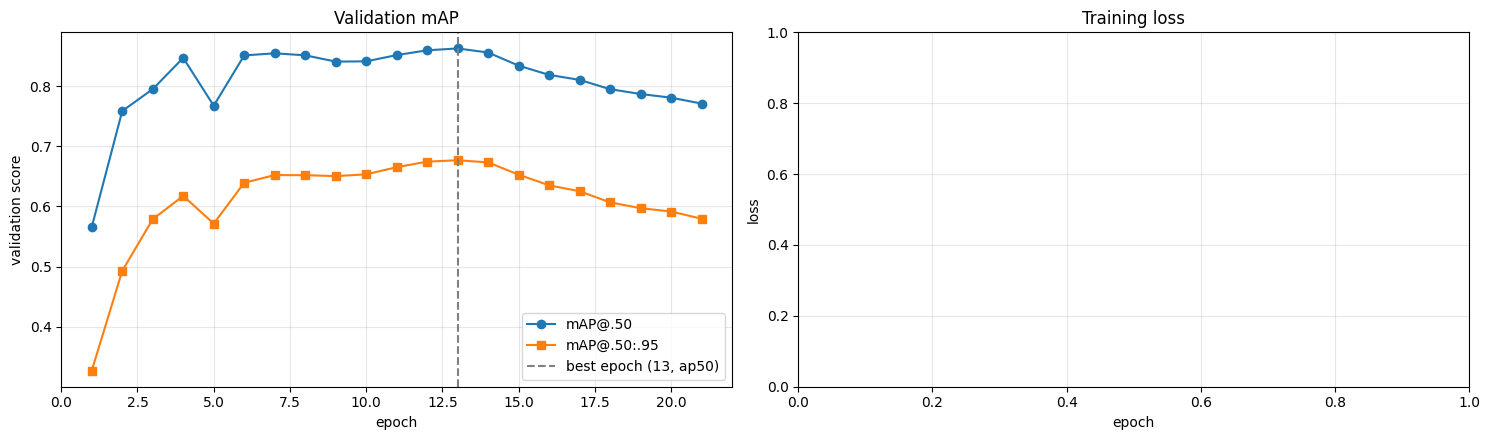

Best epoch 13: mAP@.50 = 0.8626 | mAP@.50:.95 = 0.6769
Stopped early: True | evaluations run: 21


In [10]:
# ============ CELL 9: TRAINING CURVES ============
hist = json.load(open(HIST))
E = sorted(hist["epochs"], key=lambda e: e["epoch"])
ep = [e["epoch"] for e in E]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(ep, [e["ap50"] for e in E], marker="o", label="mAP@.50")
ax[0].plot(ep, [e["ap50_95"] for e in E], marker="s", label="mAP@.50:.95")
ax[0].axvline(hist["best_epoch"], ls="--", color="gray", label=f"best epoch ({hist['best_epoch']}, {hist['monitor']})")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation score"); ax[0].set_title("Validation mAP"); ax[0].grid(alpha=.3); ax[0].legend()
loss = [(e["epoch"], e["train_loss"]) for e in E if e.get("train_loss") is not None]
if loss:
    ax[1].plot(*zip(*loss), marker="o", color="tab:red")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].set_title("Training loss"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
bestrow = next(e for e in E if e["epoch"] == hist["best_epoch"])
print(f"Best epoch {bestrow['epoch']}: mAP@.50 = {bestrow['ap50']:.4f} | mAP@.50:.95 = {bestrow['ap50_95']:.4f}")
print("Stopped early:", hist.get("stopped_early"), "| evaluations run:", len(E))

In [11]:
import glob
for pat in ("/kaggle/**/best_monitor_ckpt.pth", "/kaggle/**/best.pt", "/kaggle/**/signature.onnx", "/kaggle/**/*.zip"):
    print(pat, "->", glob.glob(pat, recursive=True)[:5])

/kaggle/**/best_monitor_ckpt.pth -> ['/kaggle/working/YOLOX/YOLOX_outputs/yolox_s_signature/best_monitor_ckpt.pth']
/kaggle/**/best.pt -> ['/kaggle/working/final_model/best.pt']
/kaggle/**/signature.onnx -> ['/kaggle/working/final_model/signature.onnx']
/kaggle/**/*.zip -> ['/kaggle/working/signature_yolox_model.zip']


## Cell 10: Load the best model + helper functions
Loads the best weights (by your `MONITOR` metric). The helpers run the network **once** per image and keep the raw output, so Cells 12 and 13 can try many thresholds without running the network again.

In [13]:
# ============ CELL 10: LOAD BEST MODEL + HELPERS ============
from yolox.exp import get_exp
from yolox.utils import postprocess
from yolox.data.data_augment import ValTransform

BEST = f"{OUT_DIR}/best_monitor_ckpt.pth"
if not os.path.exists(BEST):
    BEST = f"{OUT_DIR}/best_ckpt.pth"                       # fallback: YOLOX's own best (by mAP@.50:.95)
assert os.path.exists(BEST), "No best checkpoint found. Training must finish at least one evaluation first (Cell 8)."

exp = get_exp(EXP_FILE, None)
model = exp.get_model()
ckpt = torch.load(BEST, map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["model"])
model = model.to(DEVICE).eval()
transform = ValTransform(legacy=False)
print("Loaded:", os.path.basename(BEST), "| epoch", ckpt.get("epoch"), "| parameters: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))

@torch.no_grad()
def infer_raw(img_bgr):
    """Run the network once. Returns (raw output on CPU, resize ratio)."""
    ratio = min(exp.test_size[0] / img_bgr.shape[0], exp.test_size[1] / img_bgr.shape[1])
    img, _ = transform(img_bgr, None, exp.test_size)
    x = torch.from_numpy(img).unsqueeze(0).float().to(DEVICE)
    return model(x).cpu(), ratio

def decode(raw, ratio, conf, nms):
    """Raw output -> [[x1, y1, x2, y2, score], ...] in original image pixels."""
    out = postprocess(raw.clone(), exp.num_classes, conf, nms)[0]    # clone: postprocess edits its input
    if out is None:
        return []
    return [[float(v) for v in (*(b[:4] / ratio), b[4] * b[5])] for b in out.numpy()]

def predict_boxes(img_bgr, conf=0.3, nms=None):
    raw, ratio = infer_raw(img_bgr)
    return decode(raw, ratio, conf, exp.nmsthre if nms is None else nms)

def load_split(name, limit=None):
    folder = SPLITS[name]
    data = json.load(open(f"{A}/instances_{folder}.json"))
    gts = defaultdict(list)
    for a in data["annotations"]:
        x, y, w, h = a["bbox"]; gts[a["image_id"]].append([x, y, x + w, y + h])
    images = data["images"]
    if limit and limit < len(images):
        images = random.Random(0).sample(images, limit)
    return images, gts, f"{DATA_DIR}/{folder}"

def collect_raw(images, img_dir, desc=""):
    raws = {}
    for im in tqdm(images, desc=desc, leave=False):
        img = cv2.imread(f"{img_dir}/{im['file_name']}")
        if img is not None:
            raws[im["id"]] = infer_raw(img)
    return raws

def decode_all(raws, conf, nms):
    return {i: decode(r, ratio, conf, nms) for i, (r, ratio) in raws.items()}

def iou(a, b):
    """Intersection over Union of two boxes [x1, y1, x2, y2]."""
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

def count_prf(images, gts, preds, thr, iou_thr=0.5):
    """Greedy matching by confidence. A prediction is a TP if IoU >= iou_thr with a not-yet-used real box."""
    tp = fp = fn = 0
    fps, fns = [], []
    for im in images:
        if im["id"] not in preds:
            continue
        g, used = gts[im["id"]], set()
        for pb in sorted([p for p in preds[im["id"]] if p[4] >= thr], key=lambda p: -p[4]):
            best, bj = 0.0, -1
            for j, gb in enumerate(g):
                if j in used: continue
                v = iou(pb, gb)
                if v > best: best, bj = v, j
            if best >= iou_thr: tp += 1; used.add(bj)
            else: fp += 1; fps.append((im["id"], pb))
        for j, gb in enumerate(g):
            if j not in used: fn += 1; fns.append((im["id"], gb))
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    F = 2 * P * R / (P + R) if P + R else 0.0
    return dict(tp=tp, fp=fp, fn=fn, P=P, R=R, F1=F, fps=fps, fns=fns)

Loaded: best_monitor_ckpt.pth | epoch 13 | parameters: 8.9M


## Cell 11: What is IoU?
**IoU (Intersection over Union)** measures how well a predicted box overlaps the real (ground-truth) box. It is a number from 0 (no overlap) to 1 (perfect match):

IoU = area of overlap / area covered by both boxes together

**Why it matters for signature detection**
1. **Is a prediction correct?** With the usual threshold 0.50, a box with IoU >= 0.50 is a **True Positive**. A box with IoU < 0.50 is a **False Positive** (even if it touched part of a signature), and the signature it missed becomes a **False Negative**.
2. **mAP is built on IoU.**
   - **mAP@.50** = how many signatures are found with a loose 50% overlap.
   - **mAP@.50:.95** = the average over strict thresholds 0.50, 0.55, ..., 0.95. A high value means tight boxes that do not cut the signature and do not include a lot of empty paper.
   - **mAP@.75** = a middle ground.

| IoU | What it looks like | Meaning |
|---|---|---|
| 0.0 | Boxes are apart | Missed the signature (or guessed on empty paper) |
| < 0.5 | Partial overlap | Found it but clipped it or drew the box far too big |
| >= 0.5 | Decent overlap | Standard success threshold |
| >= 0.85 | Tight overlap | Excellent localisation |

**Precision and recall**
- **Precision** = TP / (TP + FP): of the boxes drawn, how many are real signatures. 100 boxes with only 40 real signatures = 40% precision, and a human must remove 60 mistakes.
- **Recall** = TP / (TP + FN): of the real signatures, how many were found.
- **F1** = balance of both.

The cell below draws the same real box (blue) against five predictions (green) so you can see the numbers.

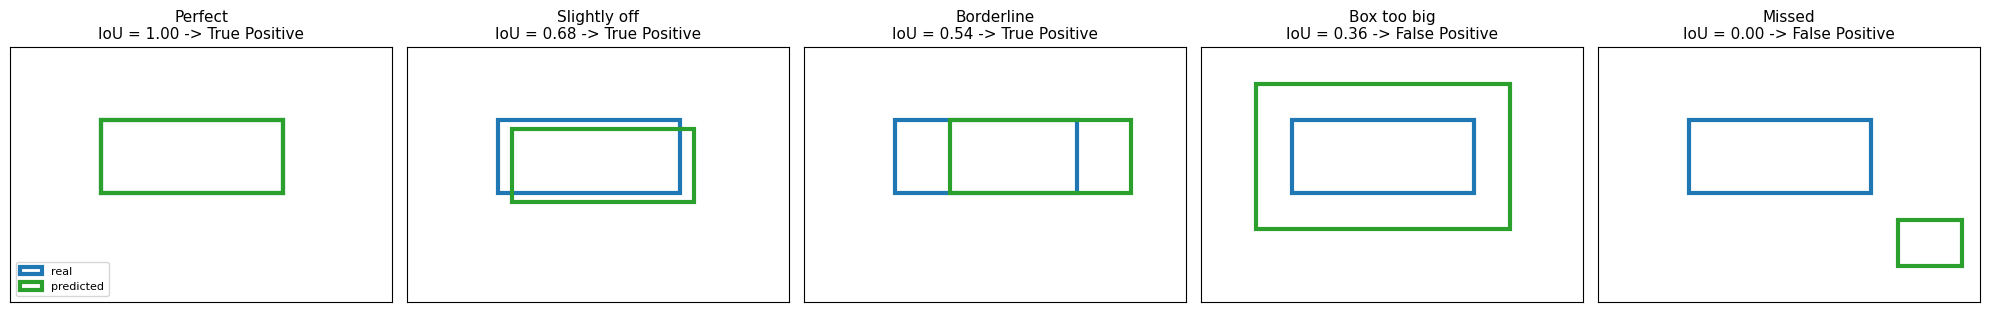

In [14]:
# ============ CELL 11: IoU - SEE IT ============
import matplotlib.patches as patches
gt_box = [100, 80, 300, 160]
demos = [("Perfect", [100, 80, 300, 160]),
         ("Slightly off", [115, 90, 315, 170]),
         ("Borderline", [160, 80, 360, 160]),
         ("Box too big", [60, 40, 340, 200]),
         ("Missed", [330, 190, 400, 240])]
fig, axs = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, pb) in zip(axs, demos):
    v = iou(pb, gt_box)
    for box, col, lab in ((gt_box, "tab:blue", "real"), (pb, "tab:green", "predicted")):
        ax.add_patch(patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, ec=col, lw=3, label=lab))
    ax.set_xlim(0, 420); ax.set_ylim(280, 0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nIoU = {v:.2f} -> {'True Positive' if v >= 0.5 else 'False Positive'}", fontsize=11)
axs[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## Cell 12: Tune the confidence threshold (fewer false positives)
The model gives every box a confidence score. **Raising the threshold removes weak guesses** (higher precision) but can also remove real signatures (lower recall). This cell tries thresholds from 0.05 to 0.95 on the **validation** set and picks:

> the threshold with the **highest F1 among those that reach `PRECISION_TARGET`** (default 95% precision). If none reaches it, it uses the best-F1 threshold and tells you.

The test set is **not** used here, so the final test numbers stay honest.

validation inference:   0%|          | 0/1500 [00:00<?, ?it/s]

Validation: 1500 images | box correct if IoU >= 0.5 | NMS = 0.45
 conf | Precision |  Recall |     F1 |     TP     FP     FN
 0.05 |     0.439 |   0.911 |  0.592 |   1717   2195    168
  0.1 |     0.523 |   0.899 |  0.661 |   1695   1545    190
 0.15 |     0.572 |   0.894 |  0.698 |   1686   1260    199
  0.2 |     0.607 |   0.885 |  0.720 |   1669   1081    216
 0.25 |     0.635 |   0.879 |  0.737 |   1657    952    228
  0.3 |     0.657 |   0.875 |  0.750 |   1649    861    236
 0.35 |     0.678 |   0.872 |  0.763 |   1643    780    242
  0.4 |     0.698 |   0.868 |  0.774 |   1637    709    248
 0.45 |     0.722 |   0.860 |  0.785 |   1622    623    263
  0.5 |     0.746 |   0.853 |  0.796 |   1607    546    278
 0.55 |     0.768 |   0.845 |  0.804 |   1592    482    293
  0.6 |     0.789 |   0.833 |  0.811 |   1571    419    314
 0.65 |     0.811 |   0.815 |  0.813 |   1536    358    349
  0.7 |     0.837 |   0.782 |  0.808 |   1474    288    411
 0.75 |     0.868 |   0.755 |  0.80

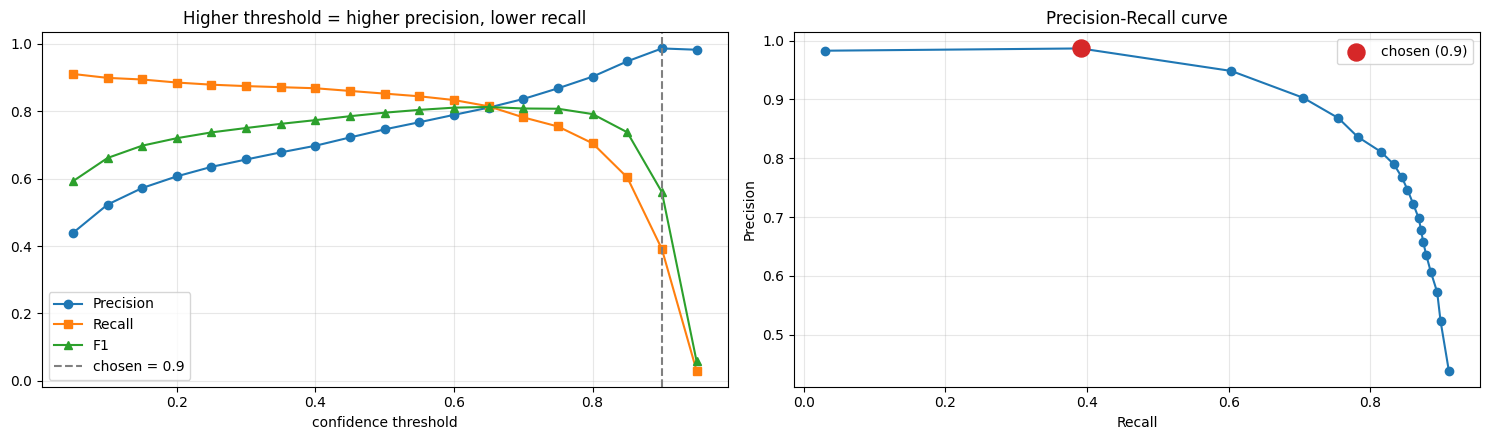

In [15]:
# ============ CELL 12: TUNE THE CONFIDENCE THRESHOLD (validation) ============
val_images, val_gts, val_dir = load_split("val", SWEEP_LIMIT)
raws_val = collect_raw(val_images, val_dir, "validation inference")
preds_val = decode_all(raws_val, conf=0.01, nms=NMS_THRESHOLD)

grid = [round(float(t), 2) for t in np.arange(0.05, 0.96, 0.05)]
rows = [(t, count_prf(val_images, val_gts, preds_val, t)) for t in grid]
print(f"Validation: {len(val_images)} images | box correct if IoU >= 0.5 | NMS = {NMS_THRESHOLD}")
print(f"{'conf':>5} | {'Precision':>9} | {'Recall':>7} | {'F1':>6} | {'TP':>6} {'FP':>6} {'FN':>6}")
for t, r in rows:
    print(f"{t:>5} | {r['P']:9.3f} | {r['R']:7.3f} | {r['F1']:6.3f} | {r['tp']:>6} {r['fp']:>6} {r['fn']:>6}")

ok = [(t, r) for t, r in rows if r["P"] >= PRECISION_TARGET]
pool = ok if ok else rows
BEST_CONF = float(max(pool, key=lambda tr: (tr[1]["F1"], -tr[0]))[0])
if ok:
    print(f"\n-> BEST_CONF = {BEST_CONF}  (highest F1 among thresholds with precision >= {PRECISION_TARGET})")
else:
    print(f"\n-> No threshold reaches precision {PRECISION_TARGET}. Using the best-F1 threshold: BEST_CONF = {BEST_CONF}")
    print("   To reduce false positives further: train longer, raise NEG_RATIO, or lower PRECISION_TARGET.")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(grid, [r["P"] for _, r in rows], marker="o", label="Precision")
ax[0].plot(grid, [r["R"] for _, r in rows], marker="s", label="Recall")
ax[0].plot(grid, [r["F1"] for _, r in rows], marker="^", label="F1")
ax[0].axvline(BEST_CONF, ls="--", color="gray", label=f"chosen = {BEST_CONF}")
ax[0].set_xlabel("confidence threshold"); ax[0].set_title("Higher threshold = higher precision, lower recall"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot([r["R"] for _, r in rows], [r["P"] for _, r in rows], marker="o")
b = dict(rows)[BEST_CONF]
ax[1].scatter([b["R"]], [b["P"]], s=150, c="tab:red", zorder=5, label=f"chosen ({BEST_CONF})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall curve"); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

## Cell 13: Tune the NMS threshold (duplicate boxes)
Sometimes the model draws two or three overlapping boxes around **one** signature. **NMS (Non-Maximum Suppression)** keeps the most confident box and removes the others that overlap it by more than the NMS IoU threshold. A **lower** NMS threshold removes overlapping boxes **more aggressively** (it deletes them, it does not merge them). Too low can delete a real second signature that sits close to the first.

This cell reuses the network outputs from Cell 12 (no extra GPU work) and picks the NMS value with the best F1 at the confidence threshold chosen above.

In [16]:
# ============ CELL 13: TUNE THE NMS THRESHOLD (validation) ============
nms_grid = [0.30, 0.40, 0.45, 0.50, 0.60, 0.65]
rows = []
for n in nms_grid:
    r = count_prf(val_images, val_gts, decode_all(raws_val, BEST_CONF, n), BEST_CONF)
    rows.append((n, r))
print(f"Validation: {len(val_images)} images | confidence threshold = {BEST_CONF}")
print(f"{'NMS':>5} | {'Precision':>9} | {'Recall':>7} | {'F1':>6} | {'TP':>6} {'FP':>6} {'FN':>6}")
for n, r in rows:
    print(f"{n:>5} | {r['P']:9.3f} | {r['R']:7.3f} | {r['F1']:6.3f} | {r['tp']:>6} {r['fp']:>6} {r['fn']:>6}")
BEST_NMS = float(max(rows, key=lambda nr: (nr[1]["F1"], -nr[0]))[0])
print(f"\n-> BEST_NMS = {BEST_NMS}  (best F1; on a tie the lower value wins)")

Validation: 1500 images | confidence threshold = 0.9
  NMS | Precision |  Recall |     F1 |     TP     FP     FN
  0.3 |     0.987 |   0.391 |  0.560 |    737     10   1148
  0.4 |     0.987 |   0.391 |  0.560 |    737     10   1148
 0.45 |     0.987 |   0.391 |  0.560 |    737     10   1148
  0.5 |     0.987 |   0.391 |  0.560 |    737     10   1148
  0.6 |     0.987 |   0.391 |  0.560 |    737     10   1148
 0.65 |     0.987 |   0.391 |  0.560 |    737     10   1148

-> BEST_NMS = 0.3  (best F1; on a tie the lower value wins)


## Cell 14: Final evaluation (validation and TEST)
Runs the model once over every image of each split with the chosen thresholds and reports:
- **mAP@.50, mAP@.50:.95, mAP@.75** (official COCO evaluation through `pycocotools`),
- **Precision, Recall, F1** at the chosen confidence threshold.

The **test** numbers are the honest ones to report: the test set was never used to pick the checkpoint or any threshold.

In [17]:
# ============ CELL 14: FINAL EVALUATION ============
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def coco_scores(split, images, preds):
    dets = [{"image_id": i, "category_id": CAT_ID, "bbox": [b[0], b[1], b[2] - b[0], b[3] - b[1]], "score": float(b[4])}
            for i, bs in preds.items() for b in bs]
    if not dets:
        return {"mAP50": 0.0, "mAP50_95": 0.0, "mAP75": 0.0}
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(f"{A}/instances_{SPLITS[split]}.json")
        dt = gt.loadRes(dets)
        ev = COCOeval(gt, dt, "bbox")
        ev.params.imgIds = [im["id"] for im in images]
        ev.evaluate(); ev.accumulate(); ev.summarize()
    s = ev.stats
    return {"mAP50": float(s[1]), "mAP50_95": float(s[0]), "mAP75": float(s[2])}

def evaluate_split(split, limit):
    images, gts, img_dir = load_split(split, limit)
    preds = {}
    for im in tqdm(images, desc=f"{split} inference"):
        img = cv2.imread(f"{img_dir}/{im['file_name']}")
        preds[im["id"]] = predict_boxes(img, 0.001, BEST_NMS) if img is not None else []
    res = coco_scores(split, images, preds)
    r = count_prf(images, gts, preds, BEST_CONF)
    res.update(precision=float(r["P"]), recall=float(r["R"]), f1=float(r["F1"]),
               tp=int(r["tp"]), fp=int(r["fp"]), fn=int(r["fn"]), images=len(images))
    return res, (images, gts, img_dir, preds)

val_res,  _ = evaluate_split("val", EVAL_LIMIT)
test_res, (test_images, test_gts, test_dir, test_preds) = evaluate_split("test", EVAL_LIMIT)
METRICS = {"val": val_res, "test": test_res, "conf_threshold": BEST_CONF, "nms_threshold": BEST_NMS, "monitor": MONITOR}

print(f"\nThresholds: confidence = {BEST_CONF} | NMS = {BEST_NMS} | box correct if IoU >= 0.5")
print(f"{'split':>5} | {'images':>6} | {'mAP@.50':>8} | {'mAP@.50:.95':>11} | {'mAP@.75':>8} | {'Precision':>9} | {'Recall':>7} | {'F1':>6} | TP / FP / FN")
for name, r in (("val", val_res), ("test", test_res)):
    print(f"{name:>5} | {r['images']:>6} | {r['mAP50']:8.3f} | {r['mAP50_95']:11.3f} | {r['mAP75']:8.3f} | "
          f"{r['precision']:9.3f} | {r['recall']:7.3f} | {r['f1']:6.3f} | {r['tp']} / {r['fp']} / {r['fn']}")
print("\nReport the TEST row. A big gap between mAP@.50 and mAP@.50:.95 means the signatures are found but the boxes are loose.")

val inference:   0%|          | 0/2418 [00:00<?, ?it/s]

test inference:   0%|          | 0/2333 [00:00<?, ?it/s]


Thresholds: confidence = 0.9 | NMS = 0.3 | box correct if IoU >= 0.5
split | images |  mAP@.50 | mAP@.50:.95 |  mAP@.75 | Precision |  Recall |     F1 | TP / FP / FN
  val |   2418 |    0.852 |       0.667 |    0.692 |     0.984 |   0.385 |  0.554 | 1171 / 19 / 1870
 test |   2333 |    0.850 |       0.668 |    0.698 |     0.985 |   0.384 |  0.553 | 1150 / 17 / 1841

Report the TEST row. A big gap between mAP@.50 and mAP@.50:.95 means the signatures are found but the boxes are loose.


## Cell 15: See the predictions and the biggest mistakes
**Green** = model prediction, **blue** = real box, **red outline** = the mistake being shown.
To try your own image, set `MY_IMAGE` to its path.

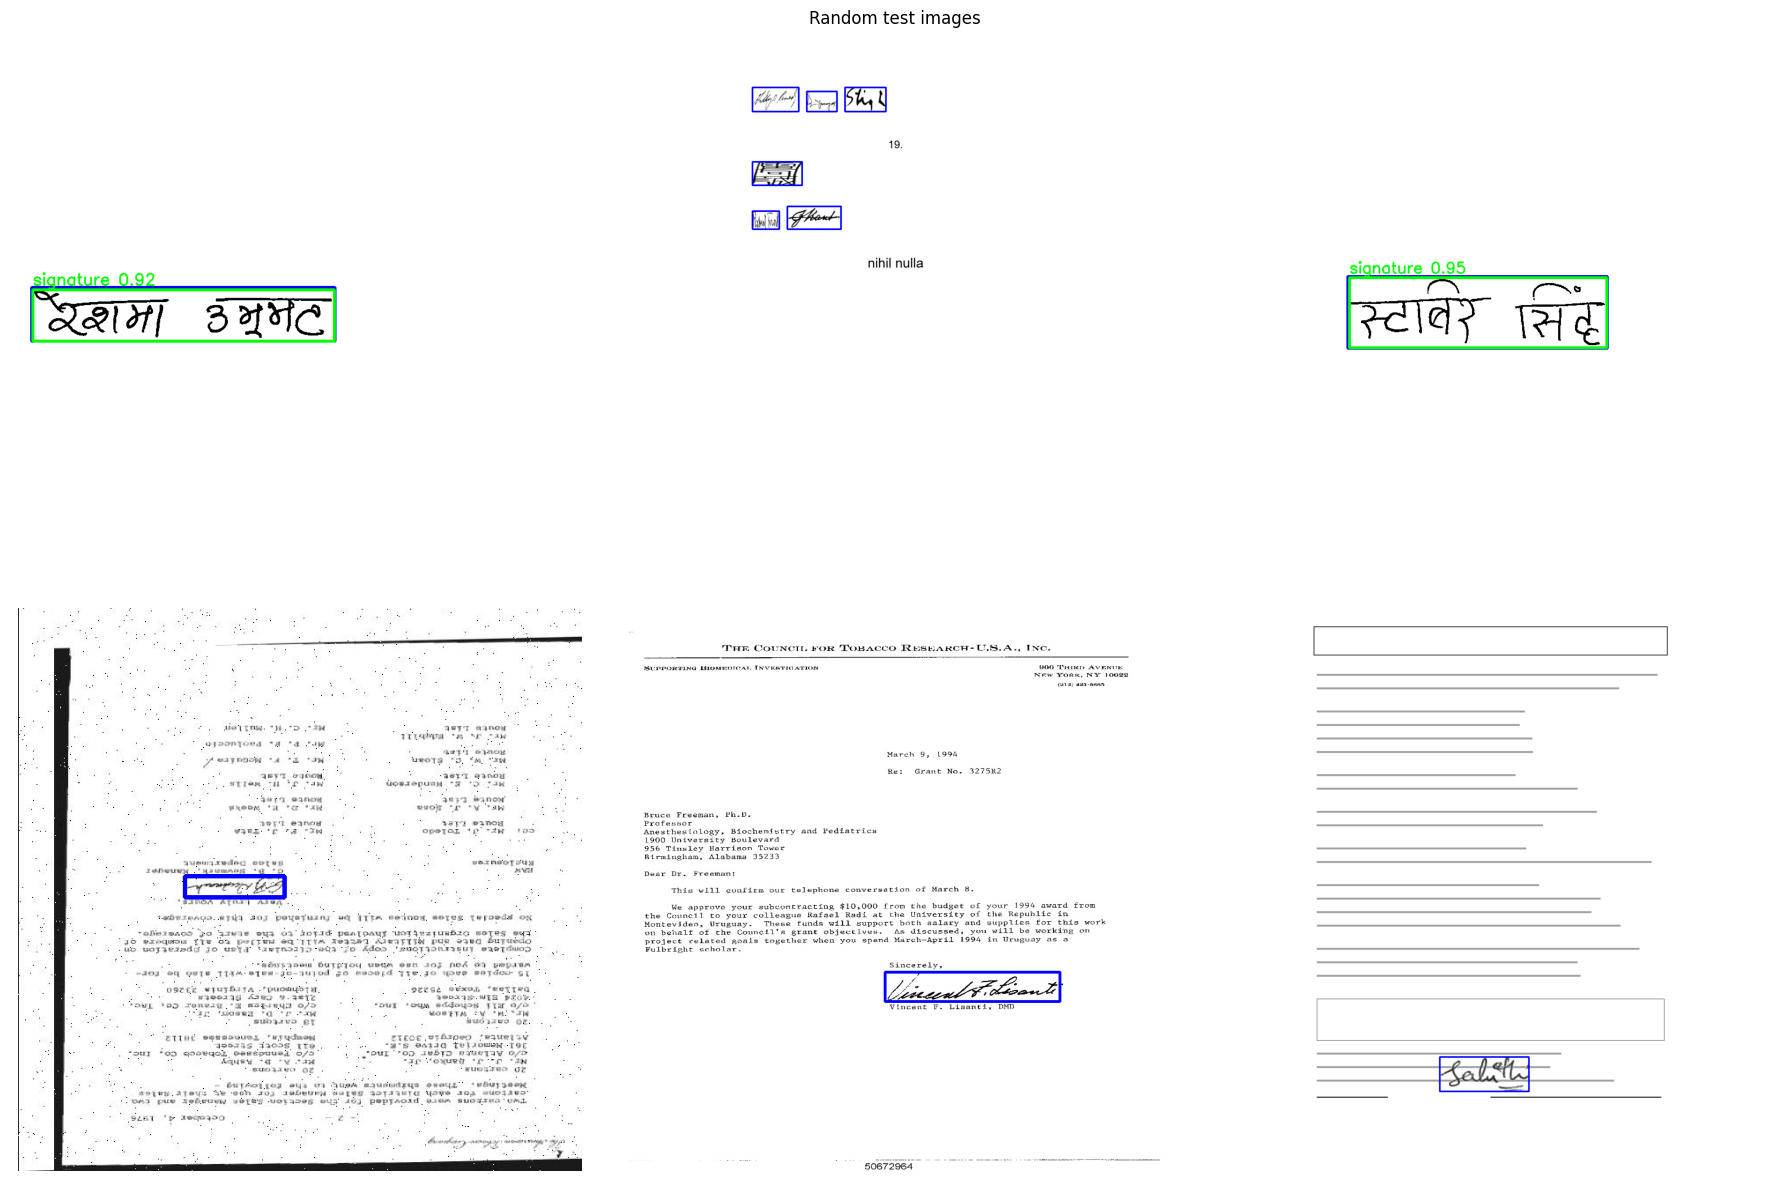

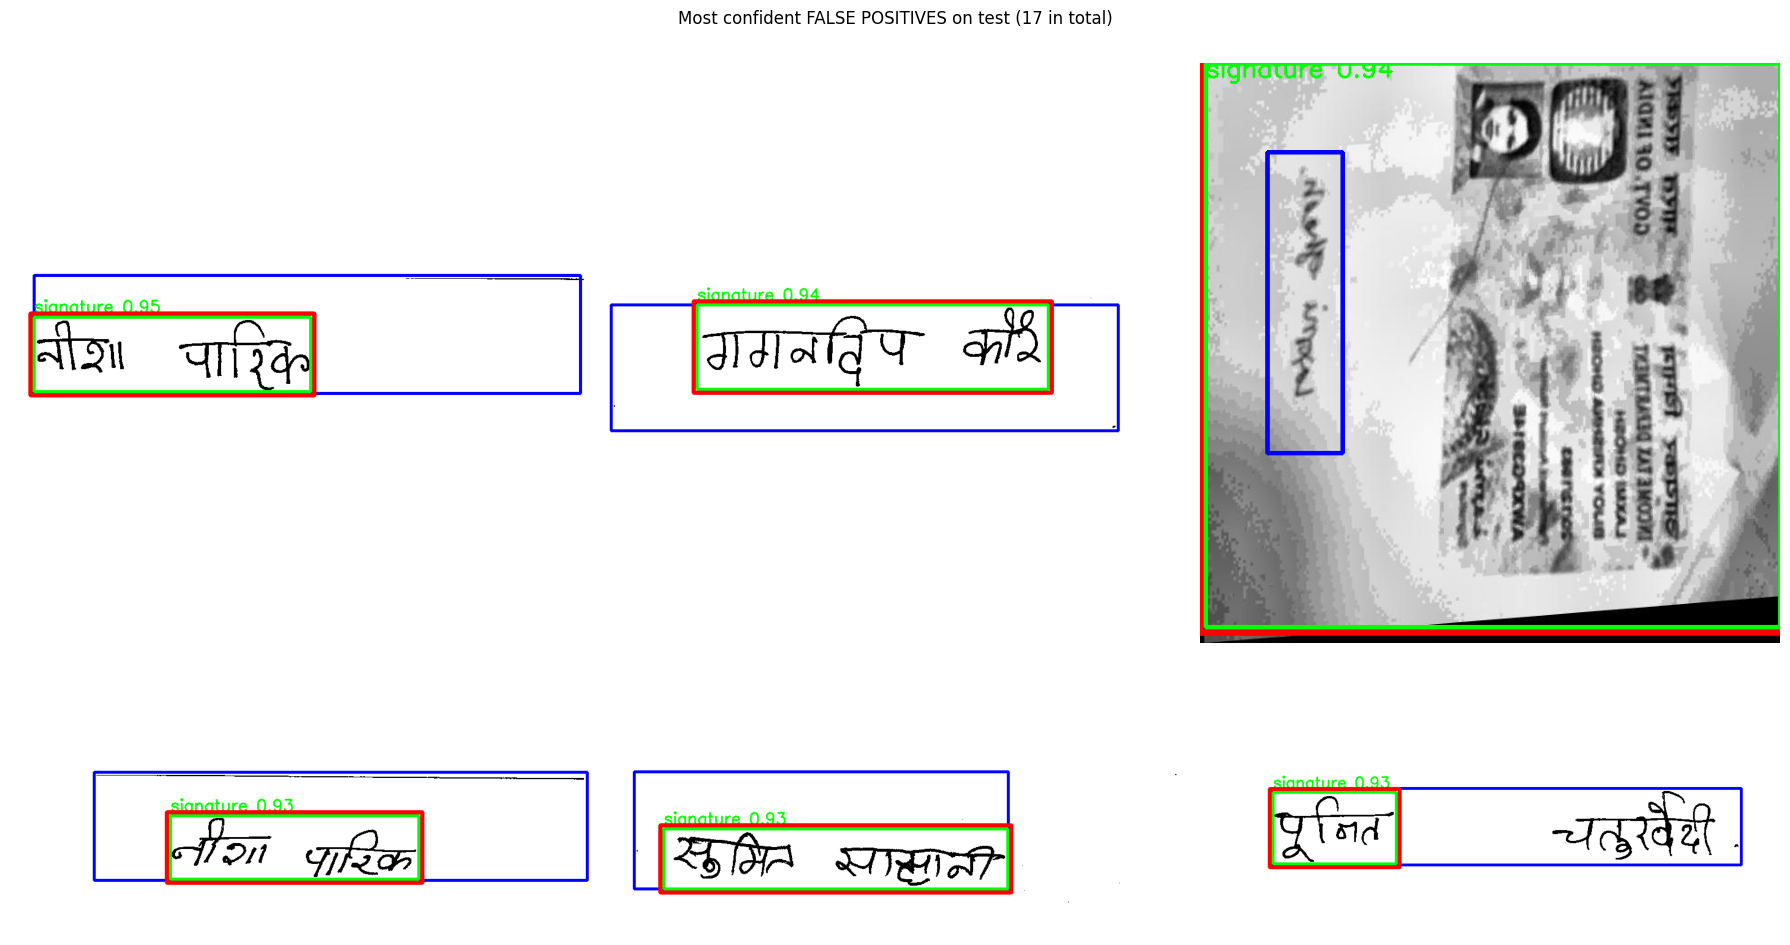

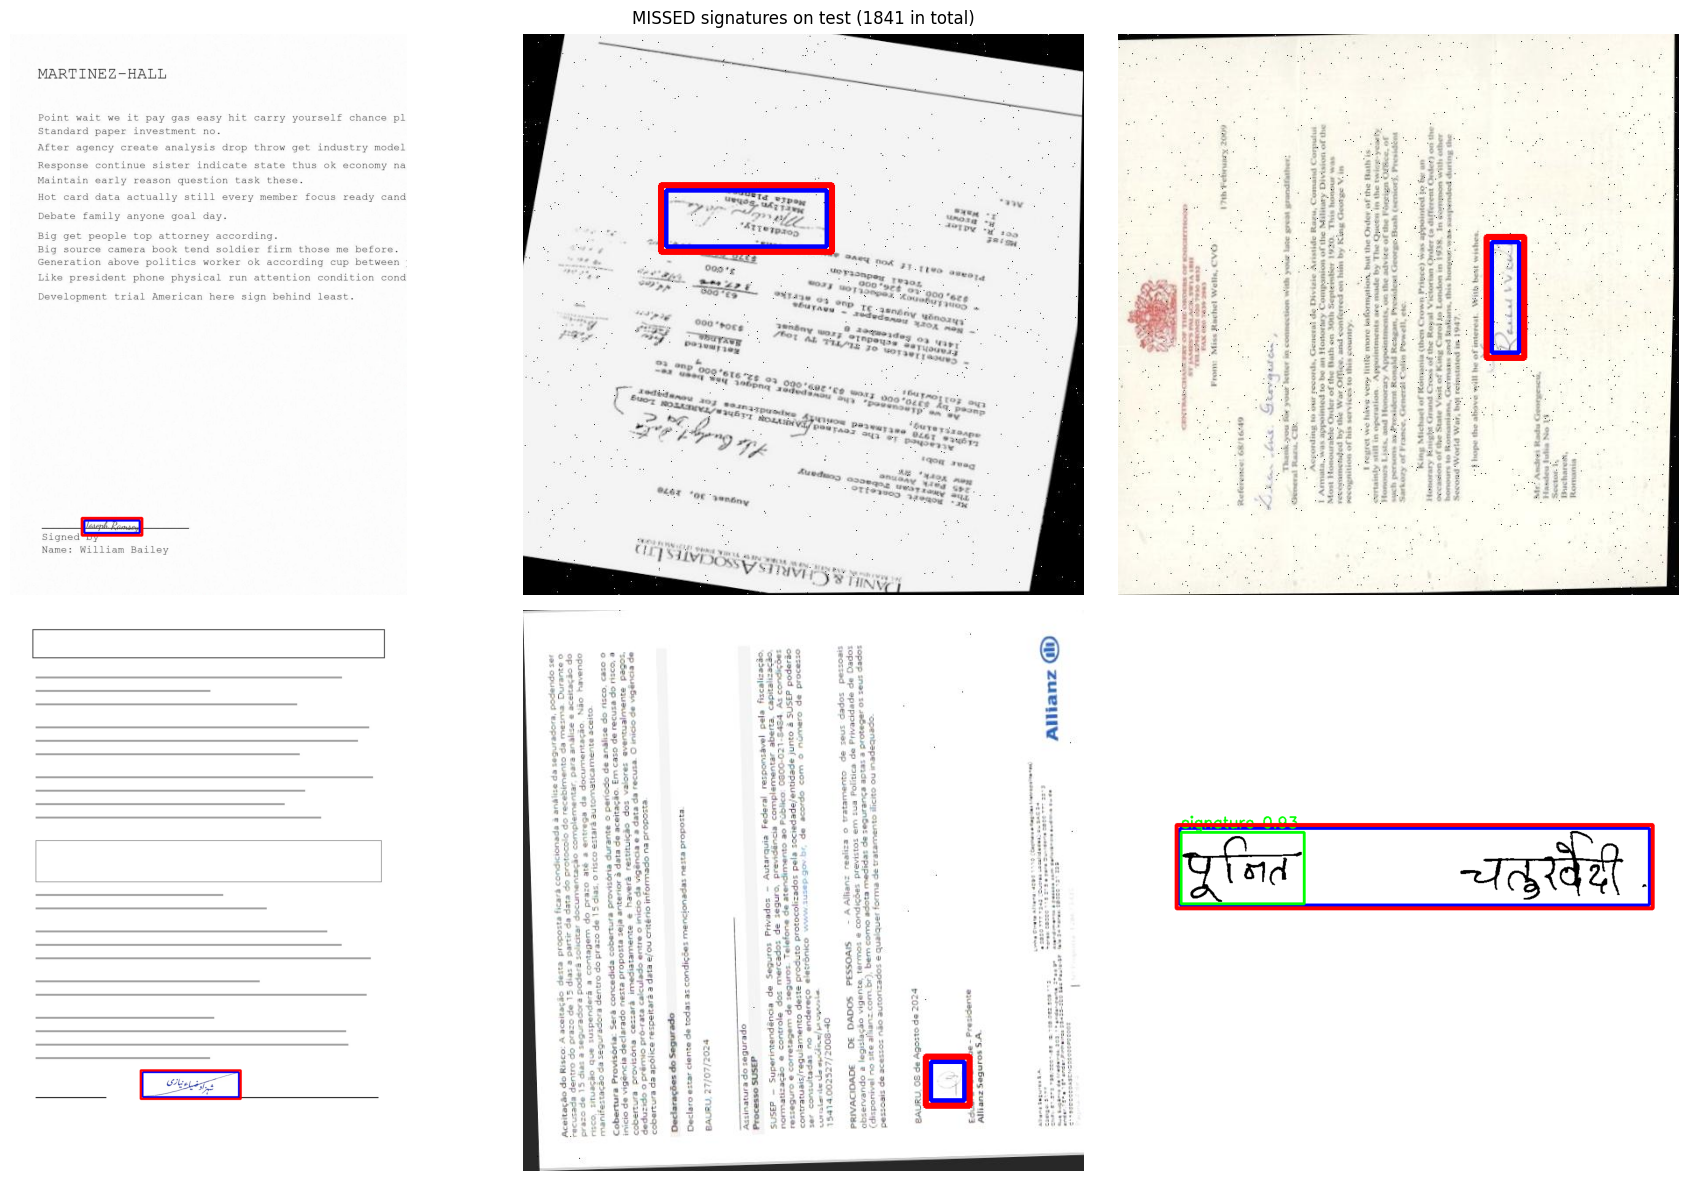

In [18]:
# ============ CELL 15: VISUALIZE PREDICTIONS AND MISTAKES ============
MY_IMAGE = ""     # e.g. "/kaggle/input/my-test/page1.jpg"  (empty = test images)

def draw(img, preds_, gt_=None):
    img = img.copy()
    for g in (gt_ or []):
        cv2.rectangle(img, tuple(map(int, g[:2])), tuple(map(int, g[2:4])), (255, 0, 0), 3)
    for b in preds_:
        x1, y1, x2, y2 = map(int, b[:4])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"signature {b[4]:.2f}", (x1, max(y1 - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

if MY_IMAGE:
    img = cv2.imread(MY_IMAGE); assert img is not None, "Could not read MY_IMAGE"
    res = predict_boxes(img, BEST_CONF, BEST_NMS)
    print("Signatures found:", len(res))
    plt.figure(figsize=(9, 9)); plt.imshow(draw(img, res)); plt.axis("off"); plt.show()
else:
    by_id = {im["id"]: im for im in test_images}
    keep_preds = lambda i: [b for b in test_preds[i] if b[4] >= BEST_CONF]

    sample = random.sample(test_images, min(6, len(test_images)))
    fig, axs = plt.subplots(2, 3, figsize=(18, 12))
    for ax in axs.ravel(): ax.axis("off")
    for ax, im in zip(axs.ravel(), sample):
        img = cv2.imread(f"{test_dir}/{im['file_name']}")
        ax.imshow(draw(img, keep_preds(im["id"]), test_gts[im["id"]]))
    fig.suptitle("Random test images"); plt.tight_layout(); plt.show()

    res = count_prf(test_images, test_gts, test_preds, BEST_CONF)
    def show_errors(items, title):
        if not items:
            print(title, "-> none found"); return
        fig, axs = plt.subplots(2, 3, figsize=(18, 12))
        for ax in axs.ravel(): ax.axis("off")
        for ax, (iid, box) in zip(axs.ravel(), items[:6]):
            img = cv2.imread(f"{test_dir}/{by_id[iid]['file_name']}")
            vis = draw(img, keep_preds(iid), test_gts[iid])
            x1, y1, x2, y2 = map(int, box[:4])
            cv2.rectangle(vis, (x1 - 6, y1 - 6), (x2 + 6, y2 + 6), (255, 0, 0), 6)     # RGB red
            ax.imshow(vis)
        fig.suptitle(title); plt.tight_layout(); plt.show()
    show_errors(sorted(res["fps"], key=lambda t: -t[1][4]), f"Most confident FALSE POSITIVES on test ({res['fp']} in total)")
    show_errors(res["fns"], f"MISSED signatures on test ({res['fn']} in total)")

## Cell 16: Export - `best.pt`, `signature.onnx`, `history.json`, `onnx_infer.py`
Creates the folder `/kaggle/working/final_model/` and a zip. Download `signature_yolox_model.zip` from the **Output** tab (or use Save Version -> Save & Run All so the files are kept).

| File | What it is |
|---|---|
| `best.pt` | Best weights (model only, about 36 MB) + class names, input size, thresholds and metrics. It is a **YOLOX** checkpoint: load it with YOLOX (`torch.load(...)["model"]`), not with Ultralytics. |
| `signature.onnx` | Same model for deployment. Box decoding is **inside** the graph, so no YOLOX code is needed to use it. |
| `history.json` | Per-epoch mAP@.50, mAP@.50:.95, loss, best epoch, whether early stopping fired. |
| `onnx_infer.py` | Stand-alone script (only `onnxruntime`, `opencv-python`, `numpy`) with your tuned thresholds as defaults. |
| `metrics.json` | Final validation and test numbers from Cell 14. |
| `yolox_s_signature.py` | The YOLOX config, needed to rebuild the model from `best.pt`. |

In [23]:
# ============ CELL 16: EXPORT ============
FINAL = f"{WORK}/final_model"
shutil.rmtree(FINAL, ignore_errors=True); os.makedirs(FINAL)
plain = lambda d: json.loads(json.dumps(d, default=float))          # numpy numbers -> plain python

# ---- 1) best.pt ----
torch.save({"model": ckpt["model"], "arch": "YOLOX-s", "classes": CLASSES,
            "input_size": [INPUT_SIZE, INPUT_SIZE], "conf_threshold": BEST_CONF, "nms_threshold": BEST_NMS,
            "epoch": ckpt.get("epoch"), "metrics": plain(METRICS)}, f"{FINAL}/best.pt")

# ---- 2) signature.onnx (box decoding inside the graph) ----
def export_onnx(out_path, size):
    from yolox.utils import replace_module
    from yolox.models.network_blocks import SiLU
    m = exp.get_model()
    m.load_state_dict(torch.load(BEST, map_location="cpu", weights_only=False)["model"])
    m = replace_module(m, torch.nn.SiLU, SiLU).eval().cpu()
    m.head.decode_in_inference = True
    dummy = torch.randn(1, 3, size, size)
    last_err = None
    for opset in (17, 13, 11):
        try:
            kw = dict(input_names=["images"], output_names=["output"], opset_version=opset)
            try:
                torch.onnx.export(m, dummy, out_path, dynamo=False, **kw)    # classic exporter on new PyTorch
            except TypeError:
                torch.onnx.export(m, dummy, out_path, **kw)                  # older PyTorch has no dynamo option
            return opset
        except Exception as e:
            last_err = e
    raise last_err

ONNX_OK = False
try:
    opset = export_onnx(f"{FINAL}/signature.onnx", INPUT_SIZE)
    ONNX_OK = True
    print("signature.onnx exported (opset", opset, ")")
except Exception as e:
    print("Direct ONNX export failed:", str(e)[:300], "\n-> trying YOLOX's own exporter")
    r = sh(f"python tools/export_onnx.py --output-name {FINAL}/signature.onnx -f {EXP_FILE} -c {BEST} --decode_in_inference --no-onnxsim", cwd=YOLOX_DIR)
    ONNX_OK = os.path.exists(f"{FINAL}/signature.onnx")
    print("YOLOX exporter:", "OK" if ONNX_OK else "FAILED\n" + (r.stdout + r.stderr)[-800:])
if ONNX_OK:
    import onnx
    onnx.checker.check_model(onnx.load(f"{FINAL}/signature.onnx"))
    print("ONNX file passed the format check")

# ---- 3) onnx_infer.py (stand-alone, tuned thresholds as defaults) ----
INFER_TEMPLATE = r"""
# onnx_infer.py - signature detection with ONNX Runtime (YOLOX-s exported by the training notebook)
# Needs only:  pip install onnxruntime opencv-python numpy
#
#   python onnx_infer.py --image page.jpg
#   python onnx_infer.py --image pages_folder --out results
#   python onnx_infer.py --image page.jpg --conf 0.6 --nms 0.4
#
# Prints one JSON line per image:
#   {"image": "...", "signatures": [{"box": [x1, y1, x2, y2], "score": 0.97}]}
import argparse, glob, json, os
import cv2
import numpy as np
import onnxruntime as ort

DEFAULT_CONF = __CONF__      # confidence threshold tuned on the validation set
DEFAULT_NMS = __NMS__        # NMS IoU threshold tuned on the validation set
DEFAULT_SIZE = (__SIZE__, __SIZE__)
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")


def load_session(model_path="signature.onnx"):
    avail = ort.get_available_providers()
    providers = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in avail]
    return ort.InferenceSession(model_path, providers=providers)


def _input_size(session):
    shp = session.get_inputs()[0].shape               # [1, 3, H, W]
    if isinstance(shp[2], int) and isinstance(shp[3], int):
        return (shp[2], shp[3])
    return DEFAULT_SIZE


def preprocess(img_bgr, size):
    # YOLOX convention: keep aspect ratio, pad with 114, BGR, values 0-255, NCHW
    h, w = img_bgr.shape[:2]
    r = min(size[0] / h, size[1] / w)
    nh, nw = int(h * r), int(w * r)
    resized = cv2.resize(img_bgr, (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((size[0], size[1], 3), 114, dtype=np.uint8)
    canvas[:nh, :nw] = resized
    blob = np.ascontiguousarray(canvas.transpose(2, 0, 1)[None], dtype=np.float32)
    return blob, r


def nms(boxes, scores, thr):
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    areas = (x2 - x1) * (y2 - y1)
    order = scores.argsort()[::-1]
    keep = []
    while order.size:
        i = order[0]
        keep.append(i)
        rest = order[1:]
        xx1, yy1 = np.maximum(x1[i], x1[rest]), np.maximum(y1[i], y1[rest])
        xx2, yy2 = np.minimum(x2[i], x2[rest]), np.minimum(y2[i], y2[rest])
        inter = np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
        iou = inter / (areas[i] + areas[rest] - inter + 1e-9)
        order = rest[iou <= thr]
    return keep


def postprocess(output, ratio, img_shape, conf, nms_thr):
    p = output[0]                                      # (N, 5 + classes): cx, cy, w, h, objectness, class scores
    scores = p[:, 4] * p[:, 5:].max(axis=1)
    m = scores >= conf
    p, scores = p[m], scores[m]
    if len(p) == 0:
        return np.zeros((0, 5), dtype=np.float32)
    boxes = np.stack([p[:, 0] - p[:, 2] / 2, p[:, 1] - p[:, 3] / 2,
                      p[:, 0] + p[:, 2] / 2, p[:, 1] + p[:, 3] / 2], axis=1) / ratio
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, img_shape[1])
    boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, img_shape[0])
    keep = nms(boxes, scores, nms_thr)
    return np.concatenate([boxes[keep], scores[keep, None]], axis=1)


def detect(session, img_bgr, conf=DEFAULT_CONF, nms_thr=DEFAULT_NMS):
    # Returns an array of [x1, y1, x2, y2, score] in original image pixels
    blob, ratio = preprocess(img_bgr, _input_size(session))
    output = session.run(None, {session.get_inputs()[0].name: blob})[0]
    return postprocess(output, ratio, img_bgr.shape, conf, nms_thr)


def draw(img_bgr, dets):
    out = img_bgr.copy()
    for x1, y1, x2, y2, s in dets:
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 3)
        cv2.putText(out, f"signature {s:.2f}", (int(x1), max(int(y1) - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    return out


def main():
    ap = argparse.ArgumentParser(description="Signature detection (ONNX)")
    ap.add_argument("--model", default=os.path.join(os.path.dirname(os.path.abspath(__file__)), "signature.onnx"))
    ap.add_argument("--image", required=True, help="image file or folder of images")
    ap.add_argument("--conf", type=float, default=DEFAULT_CONF)
    ap.add_argument("--nms", type=float, default=DEFAULT_NMS)
    ap.add_argument("--out", default=None, help="folder to save annotated images (optional)")
    args = ap.parse_args()
    session = load_session(args.model)
    if os.path.isdir(args.image):
        paths = sorted(p for p in glob.glob(os.path.join(args.image, "*")) if p.lower().endswith(IMG_EXT))
    else:
        paths = [args.image]
    if args.out:
        os.makedirs(args.out, exist_ok=True)
    for p in paths:
        img = cv2.imread(p)
        if img is None:
            print(json.dumps({"image": p, "error": "could not read image"}))
            continue
        dets = detect(session, img, args.conf, args.nms)
        sigs = [{"box": [round(float(v), 1) for v in d[:4]], "score": round(float(d[4]), 4)} for d in dets]
        print(json.dumps({"image": p, "signatures": sigs}))
        if args.out:
            cv2.imwrite(os.path.join(args.out, os.path.basename(p)), draw(img, dets))


if __name__ == "__main__":
    main()
"""
open(f"{FINAL}/onnx_infer.py", "w").write(
    INFER_TEMPLATE.lstrip("\n").replace("__CONF__", str(BEST_CONF)).replace("__NMS__", str(BEST_NMS)).replace("__SIZE__", str(INPUT_SIZE)))

# ---- 4) history.json + metrics + config ----
shutil.copy(HIST, f"{FINAL}/history.json")
json.dump(plain(METRICS), open(f"{FINAL}/metrics.json", "w"), indent=2)
shutil.copy(EXP_FILE, f"{FINAL}/{EXP_NAME}.py")

shutil.make_archive(f"{WORK}/signature_yolox_model", "zip", FINAL)
print("\nSaved in", FINAL)
for f in sorted(os.listdir(FINAL)):
    print(f"  {f:<24} {os.path.getsize(os.path.join(FINAL, f)) / 1e6:8.2f} MB")
print("\nDownload /kaggle/working/signature_yolox_model.zip from the Output tab.")


         
    



    



    
        
    
    



    
    

signature.onnx exported (opset 17 )
ONNX file passed the format check

Saved in /kaggle/working/final_model
  best.pt                     35.98 MB
  history.json                 0.00 MB
  metrics.json                 0.00 MB
  onnx_infer.py                0.01 MB
  signature.onnx              35.85 MB
  yolox_s_signature.py         0.00 MB

Download /kaggle/working/signature_yolox_model.zip from the Output tab.


## Cell 17: Test the exported ONNX files
Checks that `signature.onnx` + `onnx_infer.py` give the **same boxes as the PyTorch model**, measures CPU speed, and shows one example. Two boxes count as the same when their IoU is above 0.90.

ONNX vs PyTorch:   0%|          | 0/40 [00:00<?, ?it/s]

Images checked        : 40
PyTorch boxes         : 24
ONNX boxes            : 24
PyTorch boxes also found by ONNX (IoU > 0.90): 24 / 24
ONNX speed on CPU     : 156 ms per image (includes pre/post-processing)
RESULT: ONNX agrees with the PyTorch model -> OK to deploy


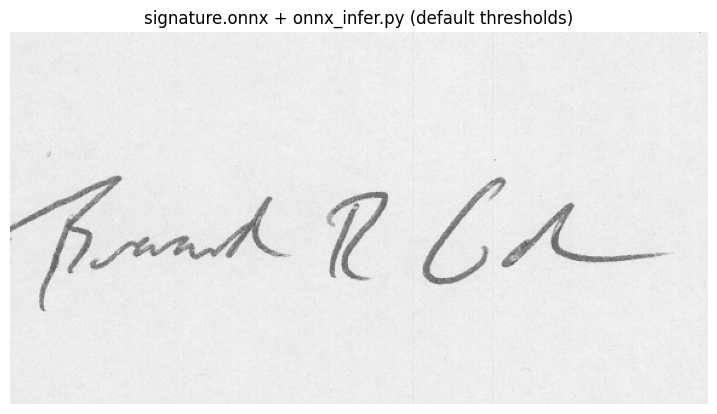


Use it anywhere:   python onnx_infer.py --image page.jpg


In [24]:
# # ============ CELL 17: TEST THE ONNX FILES ============
# import importlib.util
# assert ONNX_OK, "ONNX export did not work (see Cell 16). best.pt is still fine to use."
# spec = importlib.util.spec_from_file_location("onnx_infer", f"{FINAL}/onnx_infer.py")
# oi = importlib.util.module_from_spec(spec); spec.loader.exec_module(oi)
# import onnxruntime as ort
# sess = ort.InferenceSession(f"{FINAL}/signature.onnx", providers=["CPUExecutionProvider"])

# check_images = random.Random(1).sample(test_images, min(40, len(test_images)))
# n_torch = n_onnx = matched = 0
# t_onnx = 0.0
# for im in tqdm(check_images, desc="ONNX vs PyTorch", leave=False):
#     img = cv2.imread(f"{test_dir}/{im['file_name']}")
#     a = predict_boxes(img, BEST_CONF, BEST_NMS)
#     t0 = time.time(); b = oi.detect(sess, img, BEST_CONF, BEST_NMS); t_onnx += time.time() - t0
#     n_torch += len(a); n_onnx += len(b)
#     matched += sum(1 for pa in a if any(iou(pa, pb[:4]) > 0.90 for pb in b))
# print(f"Images checked        : {len(check_images)}")
# print(f"PyTorch boxes         : {n_torch}")
# print(f"ONNX boxes            : {n_onnx}")
# print(f"PyTorch boxes also found by ONNX (IoU > 0.90): {matched} / {n_torch}")
# print(f"ONNX speed on CPU     : {1000 * t_onnx / len(check_images):.0f} ms per image (includes pre/post-processing)")
# if n_torch and matched / n_torch >= 0.98 and abs(n_onnx - n_torch) <= max(2, 0.02 * n_torch):
#     print("RESULT: ONNX agrees with the PyTorch model -> OK to deploy")
# else:
#     print("RESULT: differences found. Boxes near the confidence threshold can flip; if the gap is large, re-run Cell 16.")

# img = cv2.imread(f"{test_dir}/{check_images[0]['file_name']}")
# plt.figure(figsize=(9, 9)); plt.imshow(cv2.cvtColor(oi.draw(img, oi.detect(sess, img)), cv2.COLOR_BGR2RGB)); plt.axis("off")
# plt.title("signature.onnx + onnx_infer.py (default thresholds)"); plt.show()
# print("\nUse it anywhere:   python onnx_infer.py --image page.jpg") 
# ============ CELL 17: TEST THE ONNX FILES ============
model = model.to(DEVICE).eval()       # FIX: Cell 16 moved the model to CPU, put it back on the GPU
import importlib.util
assert ONNX_OK, "ONNX export did not work (see Cell 16). best.pt is still fine to use."
spec = importlib.util.spec_from_file_location("onnx_infer", f"{FINAL}/onnx_infer.py")
oi = importlib.util.module_from_spec(spec); spec.loader.exec_module(oi)
import onnxruntime as ort
sess = ort.InferenceSession(f"{FINAL}/signature.onnx", providers=["CPUExecutionProvider"])

check_images = random.Random(1).sample(test_images, min(40, len(test_images)))
n_torch = n_onnx = matched = 0
t_onnx = 0.0
for im in tqdm(check_images, desc="ONNX vs PyTorch", leave=False):
    img = cv2.imread(f"{test_dir}/{im['file_name']}")
    a = predict_boxes(img, BEST_CONF, BEST_NMS)
    t0 = time.time(); b = oi.detect(sess, img, BEST_CONF, BEST_NMS); t_onnx += time.time() - t0
    n_torch += len(a); n_onnx += len(b)
    matched += sum(1 for pa in a if any(iou(pa, pb[:4]) > 0.90 for pb in b))
print(f"Images checked        : {len(check_images)}")
print(f"PyTorch boxes         : {n_torch}")
print(f"ONNX boxes            : {n_onnx}")
print(f"PyTorch boxes also found by ONNX (IoU > 0.90): {matched} / {n_torch}")
print(f"ONNX speed on CPU     : {1000 * t_onnx / len(check_images):.0f} ms per image (includes pre/post-processing)")
if n_torch and matched / n_torch >= 0.98 and abs(n_onnx - n_torch) <= max(2, 0.02 * n_torch):
    print("RESULT: ONNX agrees with the PyTorch model -> OK to deploy")
else:
    print("RESULT: differences found. Boxes near the confidence threshold can flip; if the gap is large, re-run Cell 16.")

img = cv2.imread(f"{test_dir}/{check_images[0]['file_name']}")
plt.figure(figsize=(9, 9)); plt.imshow(cv2.cvtColor(oi.draw(img, oi.detect(sess, img)), cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("signature.onnx + onnx_infer.py (default thresholds)"); plt.show()
print("\nUse it anywhere:   python onnx_infer.py --image page.jpg")

In [1]:
import os

W = "/kaggle/working"
files = {
    "signature.onnx":         f"{W}/final_model/signature.onnx",
    "best.pt":                f"{W}/final_model/best.pt",
    "history.json":           f"{W}/final_model/history.json",
    "onnx_infer.py":          f"{W}/final_model/onnx_infer.py",
    "metrics.json":           f"{W}/final_model/metrics.json",
    "signature_yolox_model.zip": f"{W}/signature_yolox_model.zip",
}
missing = 0
for name, path in files.items():
    if os.path.exists(path):
        print(f"FOUND    {name:<28} {os.path.getsize(path) / 1e6:8.2f} MB")
    else:
        print(f"MISSING  {name}")
        missing += 1

print()
if missing == 0:
    print("Session is live and all files are here. You can run the upload cell.")
elif missing == len(files):
    print("Nothing found. This session no longer has your training files.")
    print("Use the zip you downloaded and upload from your computer or Colab instead.")
else:
    print("Some files are missing. Don't upload yet. Check which ones above.")

FOUND    signature.onnx                  35.85 MB
FOUND    best.pt                         35.98 MB
FOUND    history.json                     0.00 MB
FOUND    onnx_infer.py                    0.01 MB
FOUND    metrics.json                     0.00 MB
FOUND    signature_yolox_model.zip       66.61 MB

Session is live and all files are here. You can run the upload cell.


In [4]:
# ============ UPLOAD MODEL TO HUGGING FACE (self-contained) ============
import json, os
from huggingface_hub import HfApi
from kaggle_secrets import UserSecretsClient

FOLDER       = "/kaggle/working/final_model"
REPO_NAME    = "signature-detection-yolox-s"        # repo becomes <your-username>/<this name>
PRIVATE      = True                                  # keep True until your supervisor agrees
SECRET_NAMES = ("HF_WRITE_TOKEN", "MODEL_TRAINING_TOKEN", "HF_TOKEN_SIGN", "HF_TOKEN")

need = ["signature.onnx", "best.pt", "history.json", "onnx_infer.py", "metrics.json"]
missing = [f for f in need if not os.path.exists(f"{FOLDER}/{f}")]
assert not missing, f"Missing in {FOLDER}: {missing}. Run Cell 16 first."

# ---- model card (README.md) built from your real results ----
m = json.load(open(f"{FOLDER}/metrics.json"))
t, v = m["test"], m["val"]
card = f"""---
license: apache-2.0
pipeline_tag: object-detection
tags: [yolox, onnx, signature-detection, object-detection]
---
# Signature detection (YOLOX-s)

YOLOX-s fine-tuned to find signatures on document pages (1 class: signature).
Training data: AimaArshad/signature-detection-yolox (check that dataset's license before making this repo public).

## Results (box correct if IoU >= 0.5)
| Split | mAP@.50 | mAP@.50:.95 | mAP@.75 | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| Validation | {v['mAP50']:.3f} | {v['mAP50_95']:.3f} | {v['mAP75']:.3f} | {v['precision']:.3f} | {v['recall']:.3f} | {v['f1']:.3f} |
| Test | {t['mAP50']:.3f} | {t['mAP50_95']:.3f} | {t['mAP75']:.3f} | {t['precision']:.3f} | {t['recall']:.3f} | {t['f1']:.3f} |

Thresholds: confidence {m['conf_threshold']}, NMS {m['nms_threshold']} (tuned on validation).

## Files
- signature.onnx: deployment model (box decoding inside the graph)
- onnx_infer.py: stand-alone inference script (onnxruntime, opencv, numpy)
- best.pt: YOLOX checkpoint (not an Ultralytics file)
- history.json: per-epoch mAP and loss, metrics.json: final scores
- yolox_s_signature.py: YOLOX config to rebuild the model from best.pt
"""
open(f"{FOLDER}/README.md", "w").write(card)

# ---- upload: try each secret until one has write access ----
us = UserSecretsClient()
repo_id = None
for name in SECRET_NAMES:
    try:
        token = us.get_secret(name)
    except Exception:
        continue                                     # secret not found, try the next name
    try:
        api = HfApi(token=token)
        who = api.whoami()["name"]
        rid = f"{who}/{REPO_NAME}"
        api.create_repo(rid, repo_type="model", private=PRIVATE, exist_ok=True)
        api.upload_folder(folder_path=FOLDER, repo_id=rid, repo_type="model",
                          commit_message="Add YOLOX-s signature detector")
        repo_id = rid
        print(f"Uploaded using secret '{name}' (account: {who})")
        break
    except Exception as e:
        print(f"Secret '{name}' did not work: {str(e)[:200]}")

if repo_id is None:
    raise RuntimeError("Upload failed. Add a Hugging Face WRITE token as a Kaggle secret named HF_WRITE_TOKEN "
                       "(toggle it ON for this notebook), then run this cell again.")

print("\nFiles in the repo:", api.list_repo_files(repo_id, repo_type="model"))
print("Done: https://huggingface.co/" + repo_id)

Uploaded using secret 'MODEL_TRAINING_TOKEN' (account: emaanfatimaiqbal)

Files in the repo: ['.gitattributes', 'README.md', '__pycache__/onnx_infer.cpython-313.pyc', 'best.pt', 'history.json', 'metrics.json', 'onnx_infer.py', 'signature.onnx', 'yolox_s_signature.py']
Done: https://huggingface.co/emaanfatimaiqbal/signature-detection-yolox-s


In [5]:
from huggingface_hub import HfApi
from kaggle_secrets import UserSecretsClient

api = HfApi(token=UserSecretsClient().get_secret("MODEL_TRAINING_TOKEN"))
api.delete_file("__pycache__/onnx_infer.cpython-313.pyc",
                repo_id="emaanfatimaiqbal/signature-detection-yolox-s",
                repo_type="model", commit_message="Remove cache file")
print(api.list_repo_files("emaanfatimaiqbal/signature-detection-yolox-s", repo_type="model"))

['.gitattributes', 'README.md', 'best.pt', 'history.json', 'metrics.json', 'onnx_infer.py', 'signature.onnx', 'yolox_s_signature.py']


## Notes
- **Licenses:** YOLOX = Apache 2.0, PyTorch = BSD, OpenCV = Apache 2.0, pycocotools = BSD, ONNX Runtime = MIT. No Ultralytics code. Also confirm that **your dataset's license** (listed as "other" on Hugging Face) allows what you plan to do.
- **Dataset caveat:** pages with the same form template appear in several splits, so test scores can be slightly optimistic for unseen form layouts. Test your model on a few scans from *other* sources (set `MY_IMAGE` in Cell 15).
- **Early stopping and the learning rate:** YOLOX's learning rate follows a cosine curve over `EPOCHS`, and the last 5 epochs switch off mosaic augmentation (this often gives a small final boost). Keep `EPOCHS` realistic (40-60) so early stopping is a safety net and not the normal way training ends. If training stops while the curve is still rising, raise `PATIENCE`.
- **Low recall (missed signatures)?** Train longer, try `INPUT_SIZE = 800`, or lower the confidence threshold. **Low precision (false alarms)?** Raise `NEG_RATIO` (e.g. 0.2), raise `PRECISION_TARGET`, or look at the red boxes in Cell 15 to see what fools the model (stamps, printed lines, handwriting that is not a signature).
- **Better negatives:** the best negatives are real pages without signatures (blank forms, text-only pages, stamps). If you collect some, add them to the training annotation file as images with no annotations.
- **Using the files:** `signature.onnx` + `onnx_infer.py` need no YOLOX install. `best.pt` is a YOLOX checkpoint; rebuild the model with `yolox_s_signature.py` and load `torch.load("best.pt")["model"]`.
- **Alternative:** RTMDet (MMDetection, Apache 2.0) is also allowed but much harder to install on Kaggle.